In [111]:
# Установка библиотек


# Импорты
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

from statsmodels.tsa.stattools import (
    adfuller,
    acf,
    pacf
)

from statsmodels.graphics.tsaplots import (
    plot_acf,
    plot_pacf
)

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox

from pmdarima import auto_arima

from arch import arch_model

import warnings
warnings.filterwarnings("ignore")

In [112]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import pandas as pd
import numpy as np
import pmdarima as pm
import statsmodels.api as sm
import statsmodels.tsa as tsa
import statsmodels.stats as stat
import statsmodels.stats.diagnostic as sm_diagnostic

from statsmodels.tsa.stattools import adfuller, kpss  # Добавляем adfuller и kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

from scipy import stats
from sklearn.metrics import mean_squared_error as mse

import matplotlib.dates as mdates
from matplotlib import pyplot as plt
%matplotlib inline

import warnings
warnings.filterwarnings('ignore')

from scipy.stats import shapiro, jarque_bera
from statsmodels.stats.diagnostic import acorr_breusch_godfrey as bgtest

from sklearn.metrics import mean_absolute_percentage_error

## Ставка ЦБ

In [113]:
ruonia = pd.read_excel('ключевая ставка.xlsx')

In [114]:
ruonia = ruonia[['Дата', 'Ключевая ставка, % годовых']].copy()
ruonia.columns = ['date', 'rate']
ruonia = ruonia.iloc[::-1]
ruonia

,date,rate
131,1.2014,5.5
130,2.2014,5.5
129,3.2014,7.0
128,4.2014,7.5
127,5.2014,7.5
...,...,...
4,8.2024,18.0
3,9.2024,19.0
2,10.2024,21.0
1,11.2024,21.0


In [115]:
ruonia['date'] = ruonia['date'].astype(str)

ruonia['date'] = ruonia['date'].apply(

    lambda x: x.split('.')[1] + '-' + x.split('.')[0].zfill(2)

)


In [116]:
ruonia_test = ruonia[['date', 'rate']][-12:]
ruonia_test

,date,rate
11,2024-01,16.0
10,2024-02,16.0
9,2024-03,16.0
8,2024-04,16.0
7,2024-05,16.0
6,2024-06,16.0
5,2024-07,18.0
4,2024-08,18.0
3,2024-09,19.0
2,2024-10,21.0


In [117]:
ruonia = ruonia.iloc[:-12]
ruonia

,date,rate
131,2014-01,5.5
130,2014-02,5.5
129,2014-03,7.0
128,2014-04,7.5
127,2014-05,7.5
...,...,...
16,2023-08,12.0
15,2023-09,13.0
14,2023-10,15.0
13,2023-11,15.0


## Денежная масса

In [118]:
M_2_X = pd.read_excel('М22.xlsx')


# переворачиваем таблицу
M_2_X = M_2_X.transpose()

# оставляем индексы как есть и делаем их столбцом
M_2_X = M_2_X.reset_index()

# переименование столбцов
M_2_X.columns = ['date', 'M2X']
M_2_X['date'] = M_2_X['date'].dt.strftime('%Y-%m')
# вывод
M_2_X

,date,M2X
0,2013-01,32205.7
1,2013-02,31490.6
2,2013-03,32043.4
3,2013-04,32626.9
4,2013-05,32981.1
...,...,...
140,2024-09,119977.5
141,2024-10,121759.3
142,2024-11,123407.3
143,2024-12,126512.0


In [119]:
M_2_X['growth_rate'] = np.log(M_2_X['M2X'].astype(float))

In [120]:
M_2_X_test = M_2_X[['date', 'growth_rate']][-12:]   # Последние 12 месяцев для прогноза
M_2_X_test

,date,growth_rate
133,2024-02,11.624262
134,2024-03,11.642589
135,2024-04,11.644880
136,2024-05,11.675018
137,2024-06,11.669580
138,2024-07,11.668297
139,2024-08,11.677879
140,2024-09,11.695060
141,2024-10,11.709801
142,2024-11,11.723246


In [121]:
M_2_X = M_2_X[['date', 'growth_rate']][:-12]
M_2_X

,date,growth_rate
0,2013-01,10.379899
1,2013-02,10.357444
2,2013-03,10.374847
3,2013-04,10.392892
4,2013-05,10.403690
...,...,...
128,2023-09,11.565956
129,2023-10,11.572602
130,2023-11,11.571242
131,2023-12,11.578973


In [122]:
merged_df = pd.merge(ruonia, M_2_X, on='date')
# Сохраняем датафрейм в CSV-файл
merged_df.to_csv('merged_data.csv', index=False, encoding='utf-8')


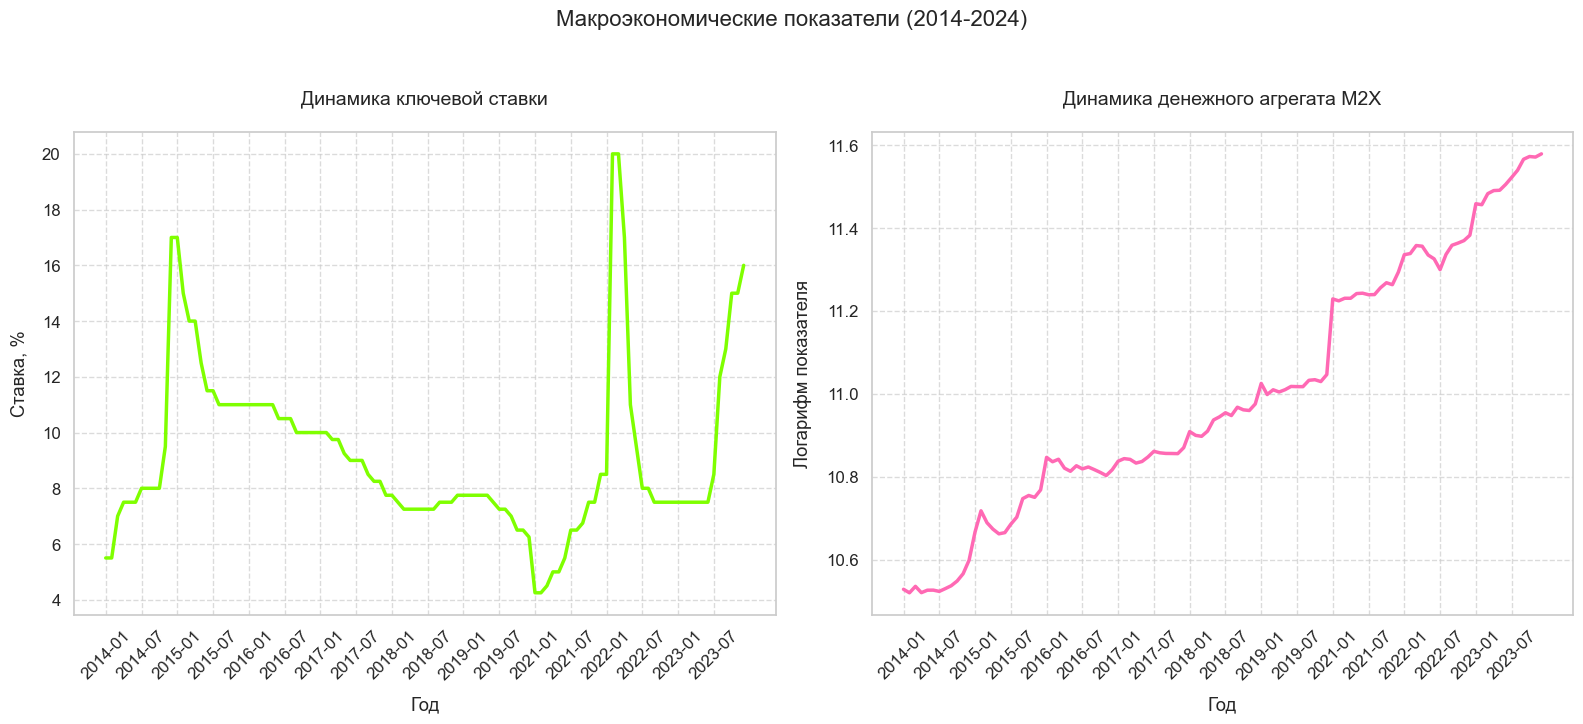

In [123]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Стиль графиков
sns.set(style="whitegrid", palette="muted", font_scale=1.1)
plt.figure(figsize=(16, 12), dpi=100)

# Функция для настройки подписей
def set_xlabels(ax, dates):
    # Выбираем каждую 6-ю дату
    step = 6
    positions = np.arange(0, len(dates), step)
    labels = [dates[i] for i in positions]
    ax.set_xticks(positions)
    ax.set_xticklabels(labels, rotation=45)

# Получаем даты для подписей
dates = merged_df['date'].astype(str).values

# 1. График процентной ставки
plt.subplot(2, 2, 1)
ax1 = sns.lineplot(data=merged_df, x='date', y='rate', color='chartreuse', linewidth=2.5)
plt.title('Динамика ключевой ставки', pad=20, fontsize=14)
plt.xlabel('Год', labelpad=10)
plt.ylabel('Ставка, %', labelpad=10)
set_xlabels(ax1, dates)
plt.grid(True, linestyle='--', alpha=0.7)

# 2. График денежного агрегата M2X
plt.subplot(2, 2, 2)
ax2 = sns.lineplot(data=merged_df, x='date', y='growth_rate', color='hotpink', linewidth=2.5)
plt.title('Динамика денежного агрегата M2X', pad=20, fontsize=14)
plt.xlabel('Год', labelpad=10)
plt.ylabel('Логарифм показателя', labelpad=10)
set_xlabels(ax2, dates)
plt.grid(True, linestyle='--', alpha=0.7)

# Общее оформление
plt.suptitle('Макроэкономические показатели (2014-2024)', y=1.02, fontsize=16)
plt.tight_layout(pad=1.0)

# Сохранение и отображение
plt.savefig('macro_indicators.png', bbox_inches='tight', dpi=120)
plt.show()

# Основная часть

# Ставка ЦБ

Шаг 1. Первый уровень ряда

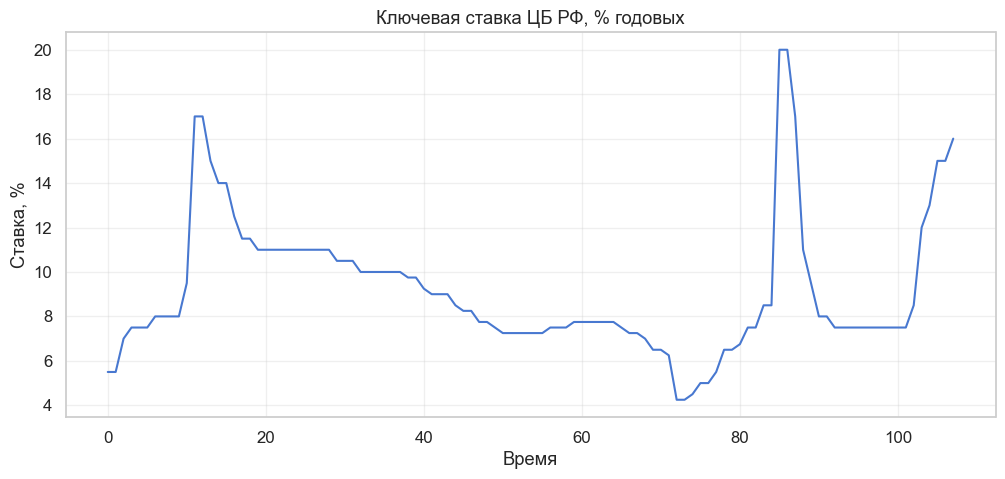

In [124]:
import matplotlib.pyplot as plt

# График уровня ряда (ставка ЦБ)
plt.figure(figsize=(12, 5))
plt.plot(merged_df['rate'], linewidth=1.5)
plt.title('Ключевая ставка ЦБ РФ, % годовых')
plt.xlabel('Время')
plt.ylabel('Ставка, %')
plt.grid(True, alpha=0.3)
plt.show()

Шаг 2. Коррелограммы

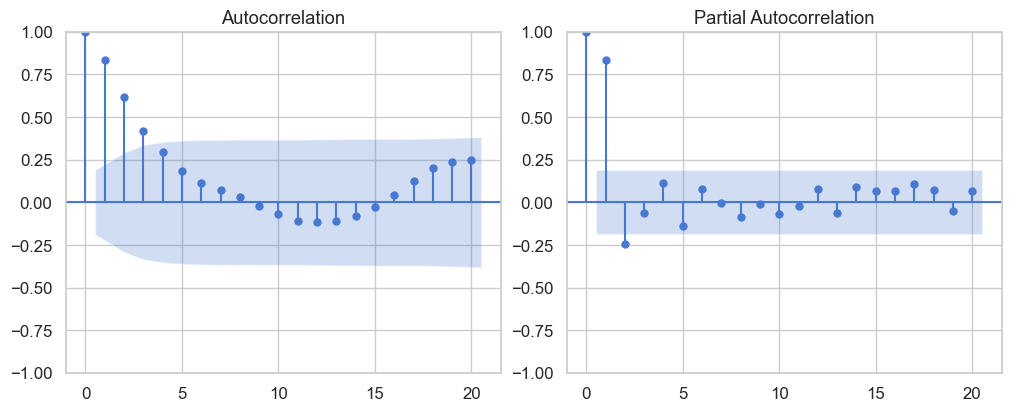

In [125]:
fig, [ax1,ax2] = plt.subplots(nrows = 1, ncols = 2, figsize = (10, 4), constrained_layout=True)

sm.graphics.tsa.plot_acf(merged_df['rate'], ax=ax1, lags = 20)
sm.graphics.tsa.plot_pacf(merged_df['rate'], ax=ax2, method = 'ywm', lags = 20)

plt.show()

Шаг 3. Проверка на стационарность

1. Тест Дики-Фуллера

In [126]:
from statsmodels.tsa.stattools import adfuller

print("==================================================")
print("     ПОДРОБНЫЙ ADF-ТЕСТ ДЛЯ УРОВНЯ РЯДА           ")
print("==================================================\n")

# --- 1. ADF с константой ---
adf_c = adfuller(merged_df['rate'], regression='c')
print("--- Модель с константой (c) ---")
print(f"ADF статистика:         {adf_c[0]:.4f}")
print(f"p-value:                {adf_c[1]:.4f}")
print("Критические значения:")
for key, value in adf_c[4].items():
    print(f"   {key}: {value:.4f}")
print("-" * 30)

# --- 2. ADF с константой + тренд ---
adf_ct = adfuller(merged_df['rate'], regression='ct')
print("--- Модель с константой и трендом (ct) ---")
print(f"ADF статистика:         {adf_ct[0]:.4f}")
print(f"p-value:                {adf_ct[1]:.4f}")
print("Критические значения:")
for key, value in adf_ct[4].items():
    print(f"   {key}: {value:.4f}")
print("-" * 30)

# --- 3. Интерпретация TS vs DS ---
print("\n[ИТОГОВЫЙ ВЫВОД]")
if adf_c[1] > 0.05 and adf_ct[1] > 0.05:
    print("→ Вывод: ряд DS (нестационарен, нужна разность, d=1)")
elif adf_c[1] > 0.05 and adf_ct[1] < 0.05:
    print("→ Вывод: ряд TS (стационарен вокруг детерминированного тренда, d=0)")
else:
    print("→ Вывод: ряд стационарен (d=0)")
print("==================================================")


     ПОДРОБНЫЙ ADF-ТЕСТ ДЛЯ УРОВНЯ РЯДА           

--- Модель с константой (c) ---
ADF статистика:         -3.3660
p-value:                0.0122
Критические значения:
   1%: -3.4936
   5%: -2.8892
   10%: -2.5815
------------------------------
--- Модель с константой и трендом (ct) ---
ADF статистика:         -3.3517
p-value:                0.0582
Критические значения:
   1%: -4.0468
   5%: -3.4528
   10%: -3.1518
------------------------------

[ИТОГОВЫЙ ВЫВОД]
→ Вывод: ряд стационарен (d=0)


2. Тест Филлипса-Перрона

In [127]:
from arch.unitroot import PhillipsPerron

pp_test = PhillipsPerron(merged_df['rate'])
print(pp_test)
# Если p-value < 0.05, ряд стационарный. 

     Phillips-Perron Test (Z-tau)    
Test Statistic                 -2.532
P-value                         0.108
Lags                               13
-------------------------------------

Trend: Constant
Critical Values: -3.49 (1%), -2.89 (5%), -2.58 (10%)
Null Hypothesis: The process contains a unit root.
Alternative Hypothesis: The process is weakly stationary.


3. KPSS

In [128]:
from statsmodels.tsa.stattools import kpss

# KPSS с трендом (для проверки TS)
kpss_ct = kpss(merged_df['rate'], regression='ct')
print(f'KPSS (с трендом): p-value = {kpss_ct[1]:.4f}')

if kpss_ct[1] < 0.05:
    print("→ KPSS: отвергаем стационарность → ряд нестационарен")
else:
    print("→ KPSS: не отвергаем стационарность → ряд стационарен")

KPSS (с трендом): p-value = 0.0431
→ KPSS: отвергаем стационарность → ряд нестационарен


Шаг 4. Проводим тесты на структурные сдвиги в R. Тут строим визуализацию теста Баи-Перрона. В R также провели тест Чоу

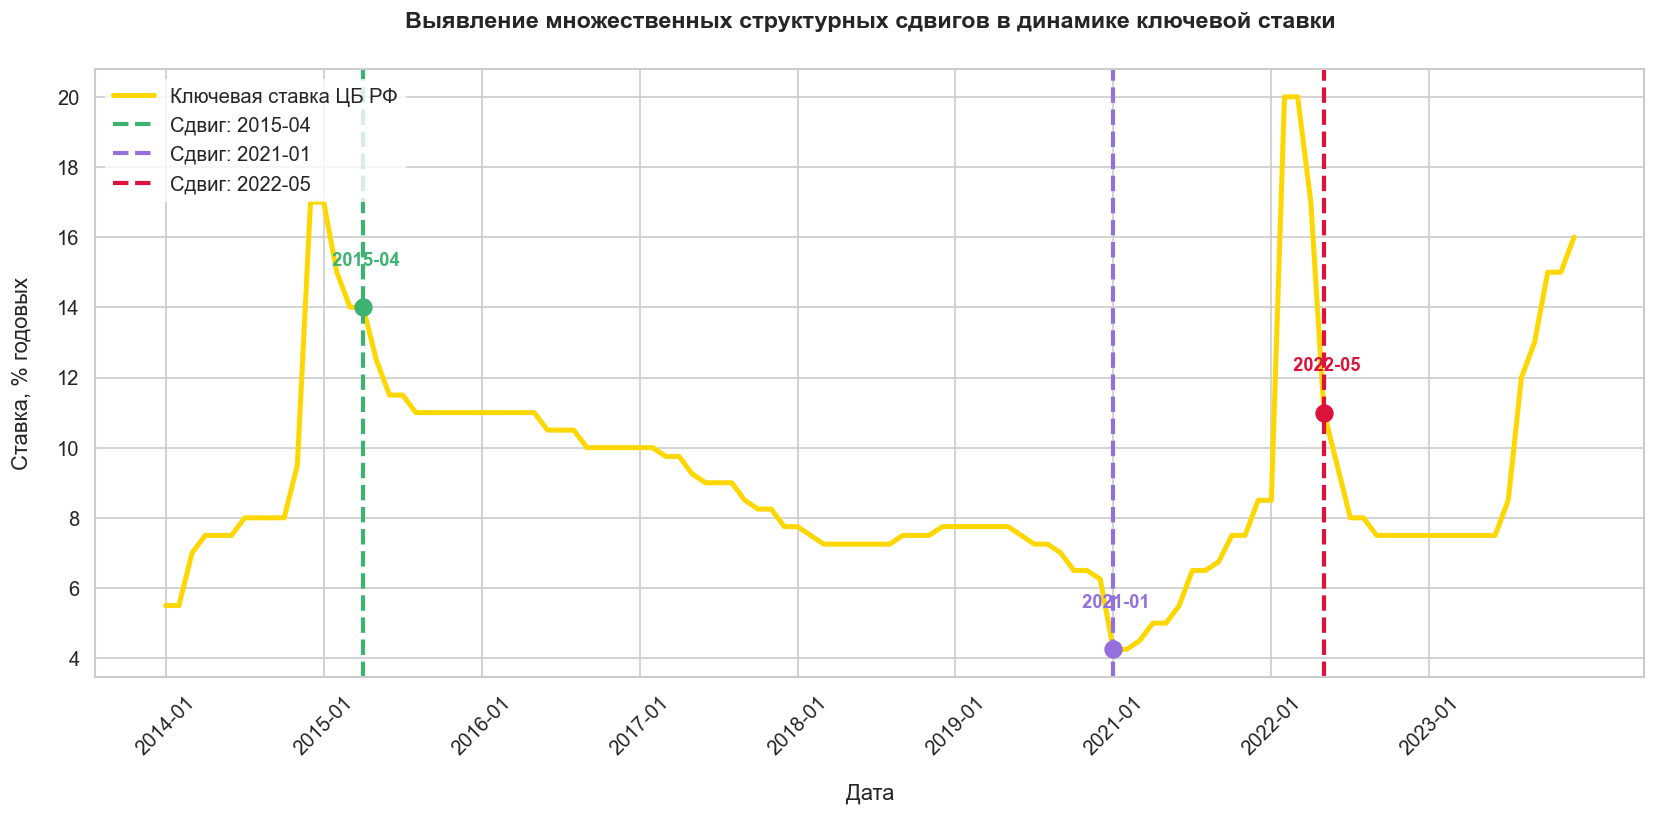

In [129]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd  # ИСПРАВЛЕНО: pandas импортируем как pd
import seaborn as sns  # ИСПРАВЛЕНО: seaborn импортируем как sns

# Создаем копию и строго переводим даты в строки
df_plot = merged_df.copy()
df_plot["date"] = df_plot["date"].astype(str)

# 1. Настройка красивого стиля
sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)
plt.figure(figsize=(14, 7), dpi=120)

# 2. Основной график динамики ставки
ax = sns.lineplot(
    data=df_plot,
    x="date",
    y="rate",
    color="gold",
    linewidth=3,
    label="Ключевая ставка ЦБ РФ",
)

# 3. Точные строковые даты сдвигов из R
break_dates = ["2015-04", "2021-01", "2022-05"]
colors = ["mediumseagreen", "mediumpurple", "crimson"]

# 4. Расставляем вертикальные линии и подписи дат
for b_date, color in zip(break_dates, colors):
    try:
        # Извлекаем значение ставки для конкретной даты
        break_rate = df_plot[df_plot["date"] == b_date]["rate"].values[0]

        # Рисуем вертикальную пунктирную линию
        plt.axvline(
            x=b_date,
            color=color,
            linestyle="--",
            linewidth=2.5,
            label=f"Сдвиг: {b_date}",
        )

        # Ставим маркер-точку на график ставки
        plt.plot(b_date, break_rate, marker="o", color=color, markersize=10)

        # Добавляем текстовую подпись над точкой
        plt.text(
            x=b_date,
            y=break_rate + 1.2,
            s=f" {b_date}",
            color=color,
            weight="bold",
            fontsize=11,
            horizontalalignment="center",
        )
    except IndexError:
        print(
            f"Предупреждение: Дата {b_date} не найдена. Проверьте формат YYYY-MM."
        )

# 5. Красивое оформление осей и заголовков
plt.title(
    "Выявление множественных структурных сдвигов в динамике ключевой ставки",
    pad=25,
    fontsize=14,
    weight="bold",
)
plt.xlabel("Дата", labelpad=15)
plt.ylabel("Ставка, % годовых", labelpad=15)

# Настройка частоты подписей оси X
step = 12
dates_array = df_plot["date"].values
positions = np.arange(0, len(dates_array), step)
labels = [dates_array[i] for i in positions]
plt.xticks(positions, labels, rotation=45)

plt.legend(loc="upper left", frameon=True, facecolor="white", edgecolor="none")
plt.tight_layout()

# 6. Сохраняем картинку
plt.savefig("structural_breaks_bai_perron_fixed.png", bbox_inches="tight", dpi=300)
plt.show()


Шаг 5. Проверяем первую разность

1. Тест Дики - Фуллера

In [130]:
from statsmodels.tsa.stattools import adfuller

# 1. Считаем первую разность ставки и удаляем возникший NaN в первой строке
merged_df['diff_rate'] = merged_df['rate'].diff()
diff_data = merged_df['diff_rate'].dropna()

print("==================================================")
print("   ПОДРОБНЫЙ ADF-ТЕСТ ДЛЯ ПЕРВОЙ РАЗНОСТИ СТАВКИ  ")
print("==================================================\n")

# --- 1. ADF с константой (основной для разностей) ---
# Проверяет, стационарен ли темп изменения вокруг постоянного среднего
adf_c = adfuller(diff_data, regression='c')
print("--- Модель с константой (c) ---")
print(f"ADF статистика:         {adf_c[0]:.4f}")
print(f"p-value:                {adf_c[1]:.4f}")
print("Критические значения:")
for key, value in adf_c[4].items():
    print(f"   {key}: {value:.4f}")
print("-" * 30)

# --- 2. ADF без константы и тренда (дополнительный) ---
# Проверяет, стационарен ли ряд строго вокруг нуля (без дрейфа)
adf_n = adfuller(diff_data, regression='n')
print("--- Модель без константы и тренда (n) ---")
print(f"ADF статистика:         {adf_n[0]:.4f}")
print(f"p-value:                {adf_n[1]:.4f}")
print("Критические значения:")
for key, value in adf_n[4].items():
    print(f"   {key}: {value:.4f}")
print("-" * 30)

# --- 3. Интерпретация ---
print("\n[ИТОГОВЫЙ ВЫВОД ДЛЯ ПЕРВОЙ РАЗНОСТИ]")
# Ориентируемся на базовую модель с константой ('c')
if adf_c[1] < 0.05:
    print("→ Вывод: Первая разность СТАЦИОНАРНА (p-value < 0.05).")
    print("  Исходный ряд официально подтвержден как интегрированный первого порядка — I(1).")
    print("  Этот ряд разностей готов к использованию в модели VAR.")
else:
    print("→ Вывод: Первая разность НЕСТАЦИОНАРНА (p-value >= 0.05).")
    print("  Нулевая гипотеза о единичном корне в разностях не отвергнута.")
    print("  Ряд имеет более высокий порядок интегрируемости (d > 1).")
print("==================================================")


   ПОДРОБНЫЙ ADF-ТЕСТ ДЛЯ ПЕРВОЙ РАЗНОСТИ СТАВКИ  

--- Модель с константой (c) ---
ADF статистика:         -7.0528
p-value:                0.0000
Критические значения:
   1%: -3.4949
   5%: -2.8898
   10%: -2.5818
------------------------------
--- Модель без константы и тренда (n) ---
ADF статистика:         -7.0558
p-value:                0.0000
Критические значения:
   1%: -2.5876
   5%: -1.9439
   10%: -1.6145
------------------------------

[ИТОГОВЫЙ ВЫВОД ДЛЯ ПЕРВОЙ РАЗНОСТИ]
→ Вывод: Первая разность СТАЦИОНАРНА (p-value < 0.05).
  Исходный ряд официально подтвержден как интегрированный первого порядка — I(1).
  Этот ряд разностей готов к использованию в модели VAR.


2. Тест Филлипса-Перрона

In [131]:
from arch.unitroot import PhillipsPerron

pp_test = PhillipsPerron(diff_data)
print(pp_test)
# Если p-value < 0.05, ряд стационарный. 

     Phillips-Perron Test (Z-tau)    
Test Statistic                 -8.206
P-value                         0.000
Lags                               13
-------------------------------------

Trend: Constant
Critical Values: -3.49 (1%), -2.89 (5%), -2.58 (10%)
Null Hypothesis: The process contains a unit root.
Alternative Hypothesis: The process is weakly stationary.


3. KPSS

In [132]:
from statsmodels.tsa.stattools import kpss

# KPSS с трендом (для проверки TS)
kpss_ct = kpss(diff_data, regression='ct')
print(f'KPSS (с трендом): p-value = {kpss_ct[1]:.4f}')

if kpss_ct[1] < 0.05:
    print("→ KPSS: отвергаем стационарность → ряд нестационарен")
else:
    print("→ KPSS: не отвергаем стационарность → ряд стационарен")

KPSS (с трендом): p-value = 0.1000
→ KPSS: не отвергаем стационарность → ряд стационарен


Шаг 6. Визуализируем первую разность

Первая разность

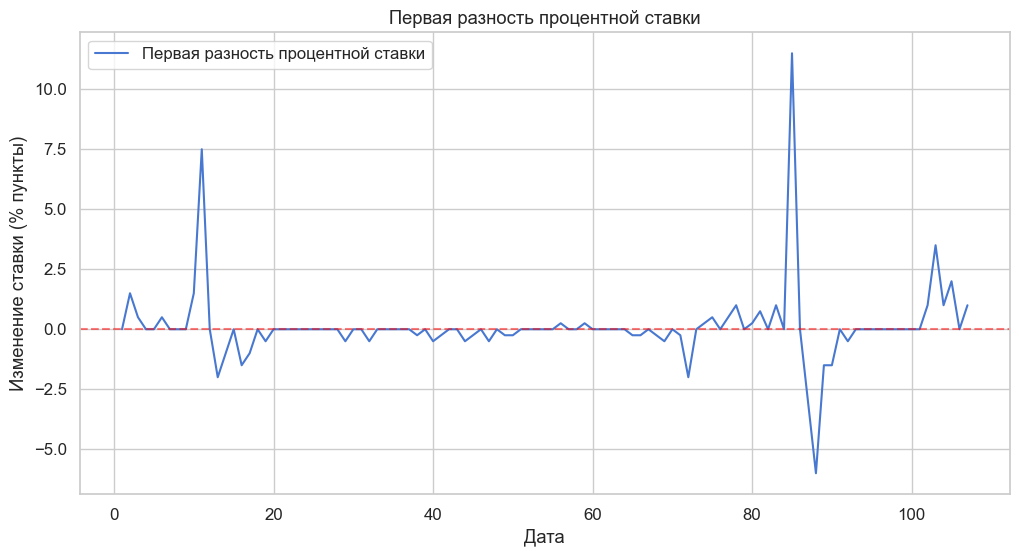

In [133]:
plt.figure(figsize=(12, 6))
plt.plot(diff_data, label='Первая разность процентной ставки')
plt.axhline(y=0, color='red', linestyle='--', alpha=0.5)
plt.title('Первая разность процентной ставки')
plt.xlabel('Дата')
plt.ylabel('Изменение ставки (% пункты)')
plt.legend()
plt.grid(True)
plt.show()

Коррелограммы

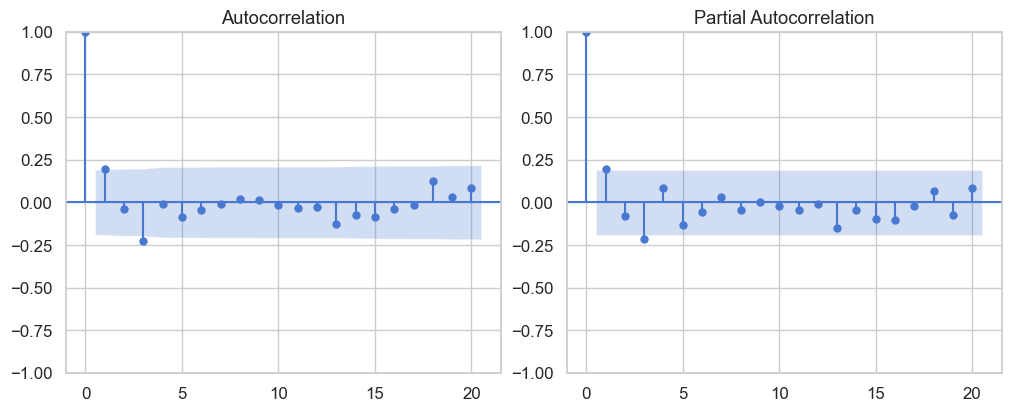

In [134]:
fig, [ax1,ax2] = plt.subplots(nrows = 1, ncols = 2, figsize = (10, 4), constrained_layout=True)

sm.graphics.tsa.plot_acf(diff_data, ax=ax1, lags=20)
sm.graphics.tsa.plot_pacf(diff_data, ax=ax2, method='ywm', lags=20)
plt.show()

Шаг 7. Добавляем дамми-переменные

Теоретическая модель №1. ARIMA(0,1,3)

In [135]:
import pandas as pd
import numpy as np
from statsmodels.tsa.arima.model import ARIMA

# 1. Принудительно приводим даты к строкам для точного поиска
merged_df['date_str'] = merged_df['date'].astype(str)

# 2. Создаем две чистые дамми-переменные
dummy_14 = pd.Series(0, index=merged_df.index, dtype=int)
dummy_22 = pd.Series(0, index=merged_df.index, dtype=int)

# Автоматически находим нужные строки по датам
idx_2014 = merged_df[merged_df['date_str'].str.startswith('2014-12')].index
idx_2022 = merged_df[merged_df['date_str'].str.startswith('2022-02')].index

# Ставим единицы в точки шоков
if len(idx_2014) > 0: dummy_14.loc[idx_2014] = 1
if len(idx_2022) > 0: dummy_22.loc[idx_2022] = 1

# 3. Собираем их в один DataFrame экзогенных факторов (матрица exog)
exog_final = pd.DataFrame({
    'dummy_2014': dummy_14,
    'dummy_2022': dummy_22
})

# 4. Оцениваем финальную модель ARIMA(0,1,3)
endog = merged_df['rate']
model_013 = ARIMA(endog, order=(0, 1, 3), exog=exog_final).fit()

print(model_013.summary())


                               SARIMAX Results                                
Dep. Variable:                   rate   No. Observations:                  108
Model:                 ARIMA(0, 1, 3)   Log Likelihood                -164.350
Date:                Thu, 28 May 2026   AIC                            340.699
Time:                        14:56:34   BIC                            356.736
Sample:                             0   HQIC                           347.200
                                - 108                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
dummy_2014     2.8744      0.306      9.384      0.000       2.274       3.475
dummy_2022     5.7400      0.335     17.127      0.000       5.083       6.397
ma.L1          0.5870      0.076      7.721      0.0

Теоретическая модель №2. ARIMA(3,1,0)

In [136]:
import pandas as pd
import numpy as np
from statsmodels.tsa.arima.model import ARIMA

# 1. Принудительно приводим даты к строкам для точного поиска
merged_df['date_str'] = merged_df['date'].astype(str)

# 2. Создаем две чистые дамми-переменные
dummy_14 = pd.Series(0, index=merged_df.index, dtype=int)
dummy_22 = pd.Series(0, index=merged_df.index, dtype=int)

# Автоматически находим нужные строки по датам
idx_2014 = merged_df[merged_df['date_str'].str.startswith('2014-12')].index
idx_2022 = merged_df[merged_df['date_str'].str.startswith('2022-02')].index

# Ставим единицы в точки шоков
if len(idx_2014) > 0: dummy_14.loc[idx_2014] = 1
if len(idx_2022) > 0: dummy_22.loc[idx_2022] = 1

# 3. Собираем их в один DataFrame экзогенных факторов (матрица exog)
exog_final = pd.DataFrame({
    'dummy_2014': dummy_14,
    'dummy_2022': dummy_22
})


endog = merged_df['rate']
model_310 = ARIMA(endog, order=(3, 1, 0), exog=exog_final).fit()

print(model_310.summary())


                               SARIMAX Results                                
Dep. Variable:                   rate   No. Observations:                  108
Model:                 ARIMA(3, 1, 0)   Log Likelihood                -164.949
Date:                Thu, 28 May 2026   AIC                            341.898
Time:                        14:56:34   BIC                            357.935
Sample:                             0   HQIC                           348.400
                                - 108                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
dummy_2014     2.8923      0.308      9.387      0.000       2.288       3.496
dummy_2022     5.7165      0.286     19.995      0.000       5.156       6.277
ar.L1          0.5770      0.071      8.177      0.0

Шаг 8. Проверяем остатки. Проводим критерий Льюнг-Бокса

     lb_stat  lb_pvalue
11  3.016164   0.990511


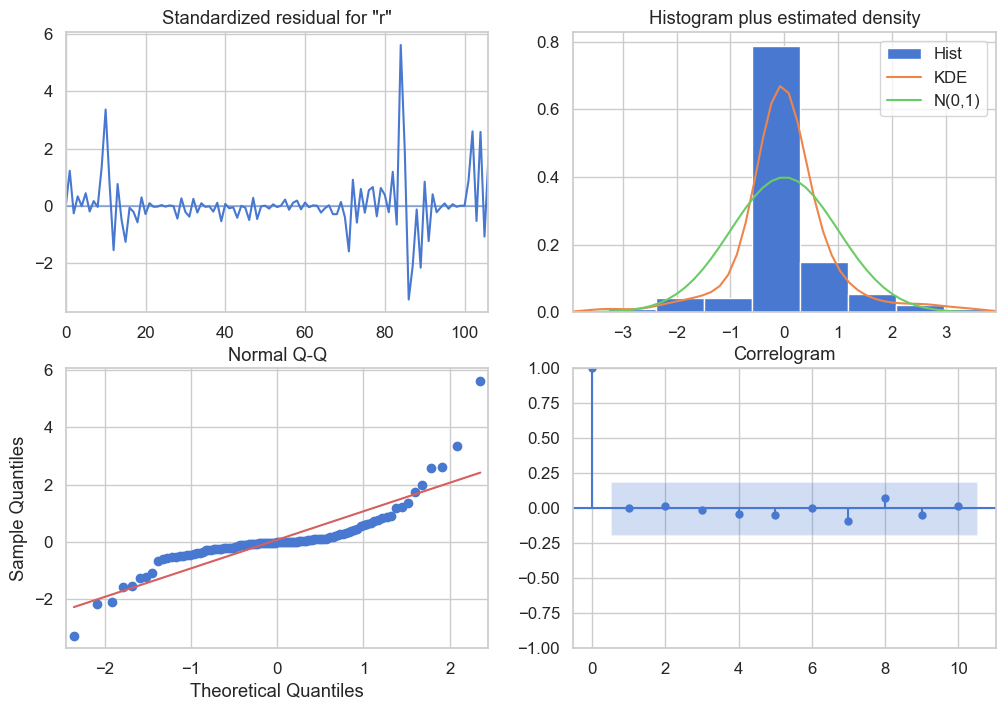

In [137]:
from statsmodels.stats.diagnostic import acorr_ljungbox
lb_test = acorr_ljungbox(model_013.resid, lags=[11], return_df=True)
print(lb_test) #Интерпретируйте результат (например: "p-value > 0.05 → остатки белые шумы").
model_013.plot_diagnostics(figsize=(12, 8))
plt.show()


Шаг 9. Тест Харке-Бера

In [138]:
from scipy.stats import jarque_bera
from statsmodels.stats.diagnostic import het_arch


residuals = model_013.resid
jb_stat, jb_pvalue = jarque_bera(residuals)

print("=" * 50)
print("ТЕСТ ЖАРКА–БЕРА (нормальность остатков)")
print("=" * 50)
print(f"Статистика Жарка–Бера: {jb_stat:.4f}")
print(f"p-value: {jb_pvalue:.6f}")
print()

if jb_pvalue > 0.05:
    print("→ p-value > 0.05 → H₀ не отвергается")
    print("→ Распределение остатков НЕ отличается от нормального")
else:
    print("→ p-value < 0.05 → H₀ отвергается")
    print("→ Распределение остатков ОТЛИЧАЕТСЯ от нормального")

ТЕСТ ЖАРКА–БЕРА (нормальность остатков)
Статистика Жарка–Бера: 429.1986
p-value: 0.000000

→ p-value < 0.05 → H₀ отвергается
→ Распределение остатков ОТЛИЧАЕТСЯ от нормального


Шаг 10. Тест Шапиро-Уилка

In [139]:
import scipy.stats as stats

# Функция возвращает статистику W и p-value
sw_stat, sw_p_value = stats.shapiro(residuals)

print("--- Результаты теста Шапиро-Уилка ---")
print(f"Статистика теста W   : {sw_stat:.3f}")
print(f"p-value              : {sw_p_value:.6f}")

if sw_p_value < 0.05:
    print("Вывод: p-value < 0.05. Отвергаем нулевую гипотезу о нормальности.")
else:
    print("Вывод: p-value >= 0.05. Остатки распределены нормально.")
print("=========================================================")


--- Результаты теста Шапиро-Уилка ---
Статистика теста W   : 0.753
p-value              : 0.000000
Вывод: p-value < 0.05. Отвергаем нулевую гипотезу о нормальности.


Шаг 11. ARCH-LM тест

In [140]:
import numpy as np
from statsmodels.stats.diagnostic import het_arch

# 1. Извлекаем чистые остатки модели (убираем первый NaN из-за d=1)
residuals_clean = model_013.resid.dropna()

print("=========================================================")
print("        ARCH-LM ТЕСТ ЭНГЕЛЯ НА ГЕТЕРОСКЕДАСТИЧНОСТЬ       ")
print("=========================================================\n")

# 2. Запускаем тест ARCH-LM
#nlags=4 означает, что мы проверяем условную гетероскедастичность до 4 лага включительно
arch_test_res = het_arch(residuals_clean, nlags=4)

# Функция возвращает 4 значения: LM-статистику, её p-value, F-статистику и её p-value
lm_stat, lm_p_val, f_stat, f_p_val = arch_test_res

print(f"LM-статистика теста    : {lm_stat:.3f}")
print(f"p-value (LM-test)      : {lm_p_val:.6f}")
print(f"F-статистика теста    : {f_stat:.3f}")
print(f"p-value (F-test)       : {f_p_val:.6f}")
print("---------------------------------------------------------")

if lm_p_val < 0.05:
    print("Вывод: p-value < 0.05. Отвергаем нулевую гипотезу.")
    print("→ В остатках ПРИСУТСТВУЮТ ARCH-эффекты (гетероскедастичность).")
    print("→ Рекомендация для эссе: требуется построение моделей ARCH/GARCH.")
else:
    print("Вывод: p-value >= 0.05. Нет оснований отвергать нулевую гипотезу.")
    print("→ ARCH-эффекты отсутствуют, дисперсия остатков гомоскедастична.")
print("=========================================================")


        ARCH-LM ТЕСТ ЭНГЕЛЯ НА ГЕТЕРОСКЕДАСТИЧНОСТЬ       

LM-статистика теста    : 13.391
p-value (LM-test)      : 0.009515
F-статистика теста    : 3.658
p-value (F-test)       : 0.008026
---------------------------------------------------------
Вывод: p-value < 0.05. Отвергаем нулевую гипотезу.
→ В остатках ПРИСУТСТВУЮТ ARCH-эффекты (гетероскедастичность).
→ Рекомендация для эссе: требуется построение моделей ARCH/GARCH.


Шаг 12. Прогнозирование и расчёт метрик

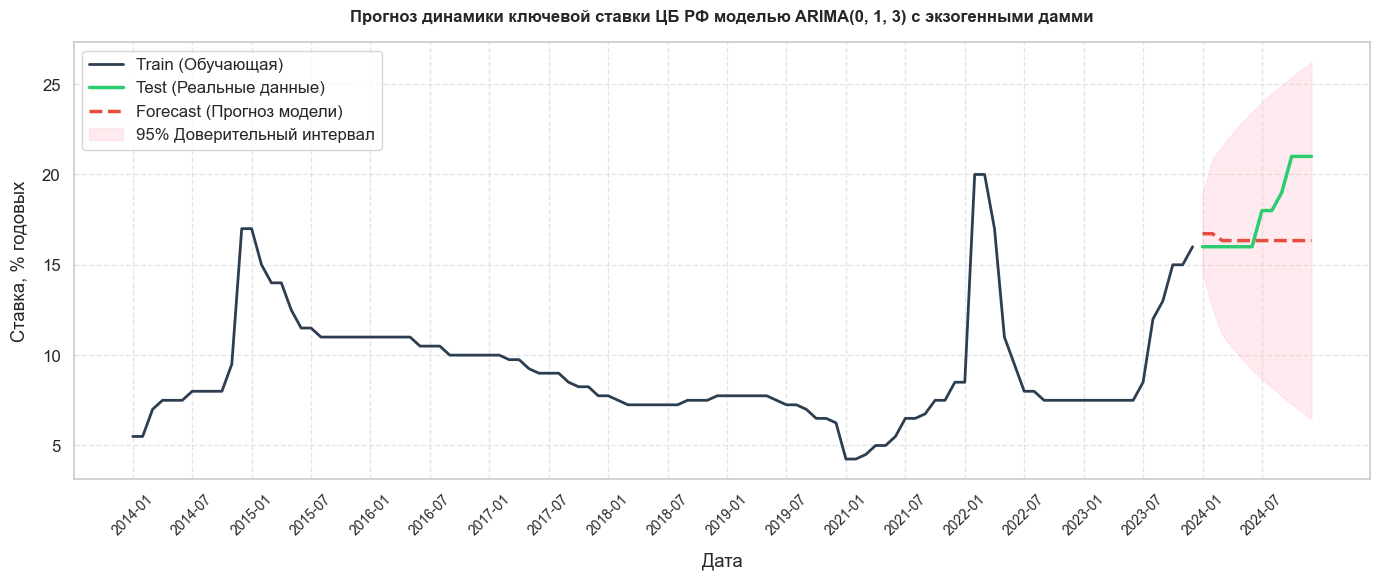

     КАЧЕСТВО ПРОГНОЗИРОВАНИЯ МОДЕЛИ (OUT-OF-SAMPLE)      
Средняя абсолютная ошибка (MAE)          : 1.897 п.п.
Средняя относительная ошибка (MAPE)       : 9.71%


In [141]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# =========================================================================
# 1. ПОДГОТОВКА EXOG ДЛЯ ПРОГНОЗА (ДВЕ дамми-переменные из нулей)
# =========================================================================
forecast_steps = len(ruonia_test)

# Матрица будущего exog должна содержать точно такие же столбцы, как при обучении!
exog_test = pd.DataFrame(
    {
        "dummy_2014": [0] * forecast_steps,
        "dummy_2022": [0] * forecast_steps,
    },
    index=ruonia_test.index,
)

# =========================================================================
# 2. РАСЧЕТ ПРОГНОЗА С ИСПРАВЛЕННЫМ EXOG
# =========================================================================
# Передаем подготовленный exog_test внутрь функции get_forecast
forecast = model_013.get_forecast(steps=forecast_steps, exog=exog_test)
forecast_mean = forecast.predicted_mean
forecast_ci = forecast.conf_int()

# =========================================================================
# 3. ПОСТРОЕНИЕ ИСПРАВЛЕННОЙ ВИЗУАЛИЗАЦИИ
# =========================================================================
plt.figure(figsize=(14, 6), dpi=100)

# Принудительно переводим даты в строки, чтобы matplotlib не путал типы на оси X
train_dates = merged_df["date"].astype(str).values
test_dates = ruonia_test["date"].astype(str).values
all_dates = np.concatenate([train_dates, test_dates])

# Строим графики по массивам значений
plt.plot(train_dates, merged_df["rate"].values, label="Train (Обучающая)", color="#2c3e50", linewidth=2)
plt.plot(test_dates, ruonia_test["rate"].values, label="Test (Реальные данные)", color="#2ecc71", linewidth=2.5)
plt.plot(test_dates, forecast_mean.values, label="Forecast (Прогноз модели)", color="#e74c3c", linestyle="--", linewidth=2.5)

# Доверительный интервал (розовая зона)
plt.fill_between(
    test_dates,
    forecast_ci.iloc[:, 0].values,
    forecast_ci.iloc[:, 1].values,
    color="pink",
    alpha=0.3,
    label="95% Доверительный интервал",
)

# Настройка читаемости оси X (выводим каждую 6-ю дату)
step = 6
positions = np.arange(0, len(all_dates), step)
labels = [all_dates[i] for i in positions]
plt.xticks(positions, labels, rotation=45, fontsize=10)

plt.title("Прогноз динамики ключевой ставки ЦБ РФ моделью ARIMA(0, 1, 3) c экзогенными дамми", fontsize=12, weight="bold", pad=15)
plt.xlabel("Дата", labelpad=10)
plt.ylabel("Ставка, % годовых", labelpad=10)
plt.legend(loc="upper left", frameon=True)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

plt.show()

# =========================================================================
# 4. РАСЧЕТ И ИТОГОВЫЙ ВЫВОД МЕТРИКИ MAPE
# =========================================================================
actual_values = ruonia_test["rate"].values
forecast_values = forecast_mean.values

mape = np.mean(np.abs((actual_values - forecast_values) / actual_values)) * 100
mae = np.mean(np.abs(actual_values - forecast_values))

print("=========================================================")
print("     КАЧЕСТВО ПРОГНОЗИРОВАНИЯ МОДЕЛИ (OUT-OF-SAMPLE)      ")
print("=========================================================")
print(f"Средняя абсолютная ошибка (MAE)          : {mae:.3f} п.п.")
print(f"Средняя относительная ошибка (MAPE)       : {mape:.2f}%")
print("=========================================================")


Шаг 13. Ошибка прогноза

Средняя абсолютная процентная ошибка (MAPE): 9.71%

Сравнение прогноза с реальными значениями:
    Actual   Forecast     Error
11    16.0  16.723587 -0.723587
10    16.0  16.720330 -0.720330
9     16.0  16.340363 -0.340363
8     16.0  16.340363 -0.340363
7     16.0  16.340363 -0.340363
6     16.0  16.340363 -0.340363
5     18.0  16.340363  1.659637
4     18.0  16.340363  1.659637
3     19.0  16.340363  2.659637
2     21.0  16.340363  4.659637
1     21.0  16.340363  4.659637
0     21.0  16.340363  4.659637


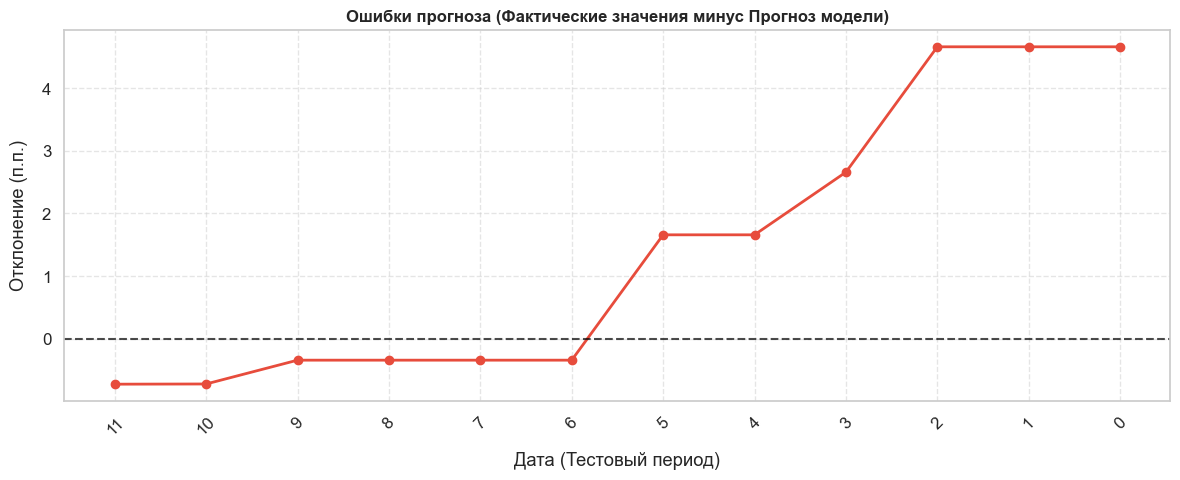

In [142]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_percentage_error

# =========================================================================
# 1. ИСПРАВЛЕНО: Генерация прогноза с учетом 2-х дамми
# =========================================================================
forecast_steps = len(ruonia_test)

# Создаем пустую exog матрицу для будущего периода (без шоков)
exog_test = pd.DataFrame({
    'dummy_2014': [0] * forecast_steps,
    'dummy_2022': [0] * forecast_steps
}, index=ruonia_test.index)

# Делаем прогноз от правильной модели model_013
forecast = model_013.get_forecast(steps=forecast_steps, exog=exog_test)
forecast_mean = forecast.predicted_mean

# =========================================================================
# 2. ВАШ КОД: Выравнивание индексов и расчет MAPE (абсолютно верно!)
# =========================================================================
forecast_mean.index = ruonia_test.index

# Расчет MAPE
mape = mean_absolute_percentage_error(ruonia_test['rate'], forecast_mean) * 100
print(f"Средняя абсолютная процентная ошибка (MAPE): {mape:.2f}%\n")

# Анализ точности прогноза (Таблица сравнения)
comparison = pd.DataFrame({
    'Actual': ruonia_test['rate'],
    'Forecast': forecast_mean,
    'Error': ruonia_test['rate'] - forecast_mean
})
print("Сравнение прогноза с реальными значениями:")
print(comparison)

# =========================================================================
# 3. ВАШ КОД: График ошибок прогноза (абсолютно верно!)
# =========================================================================
plt.figure(figsize=(12, 5), dpi=100)
plt.plot(comparison.index.astype(str), comparison['Error'], marker='o', color='#e74c3c', linewidth=2)
plt.axhline(0, color='black', linestyle='--', alpha=0.7)
plt.title('Ошибки прогноза (Фактические значения минус Прогноз модели)', fontsize=12, weight='bold')
plt.xlabel('Дата (Тестовый период)', labelpad=10)
plt.ylabel('Отклонение (п.п.)', labelpad=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# Денежная масса

Шаг 1. Первый уровень ряда

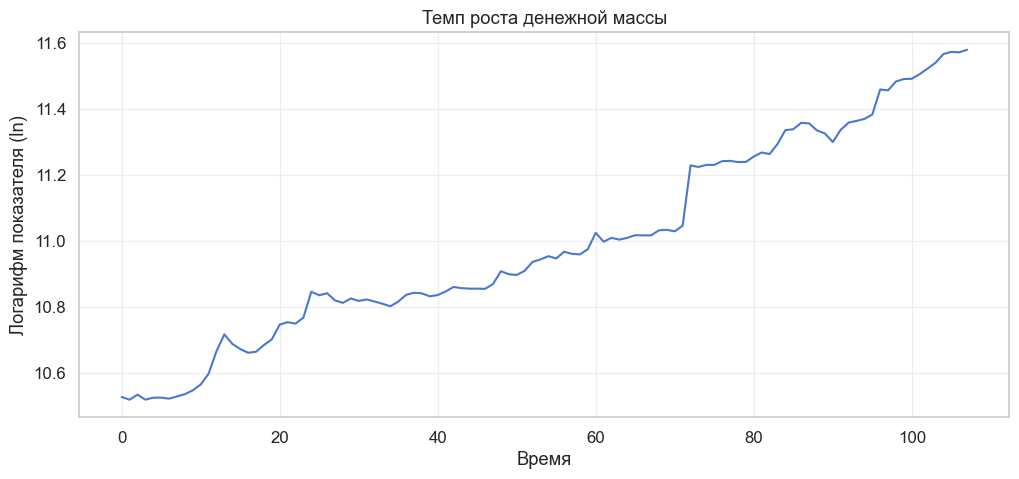

In [143]:
# График уровня ряда (ставка ЦБ)
plt.figure(figsize=(12, 5))
plt.plot(merged_df['growth_rate'], linewidth=1.5)
plt.title('Темп роста денежной массы')
plt.xlabel('Время')
plt.ylabel('Логарифм показателя (ln)')
plt.grid(True, alpha=0.3)
plt.show()

Шаг 2. Коррелограммы

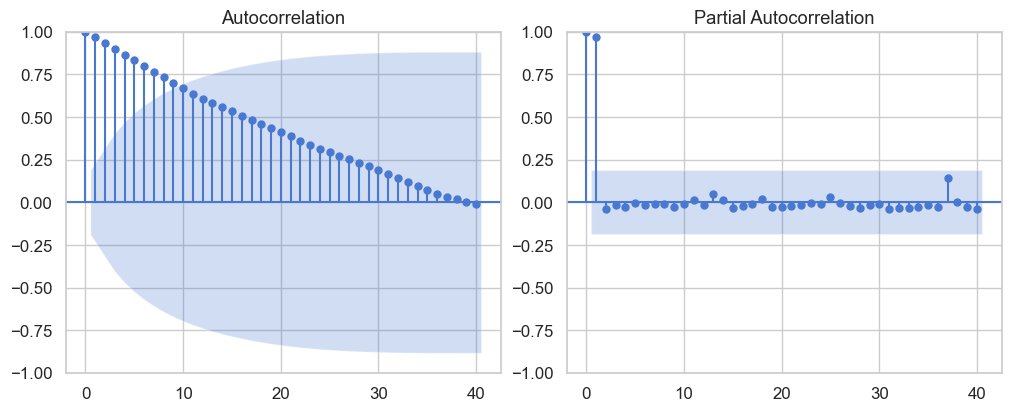

In [144]:
fig, [ax1,ax2] = plt.subplots(nrows = 1, ncols = 2, figsize = (10, 4), constrained_layout=True)

sm.graphics.tsa.plot_acf(merged_df['growth_rate'], ax=ax1, lags=40)
sm.graphics.tsa.plot_pacf(merged_df['growth_rate'], ax=ax2, method = 'ywm', lags=40)

plt.show()

Шаг 3. Проверяем сезонность

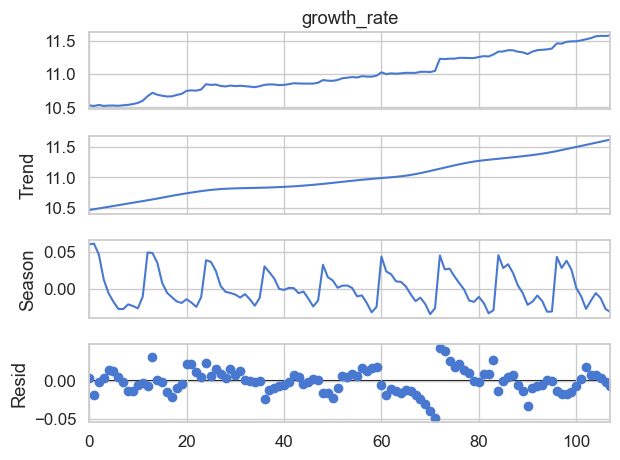

Сезонность слабая — можно исключить


In [145]:
from statsmodels.tsa.seasonal import STL
import matplotlib.pyplot as plt

# Применяем STL-декомпозицию
stl = STL(merged_df['growth_rate'], period=12)  # период = 12 для месячных данных
res = stl.fit()

# Визуализируем результат
res.plot()
plt.show()

if res.seasonal.std() < 0.5 * merged_df['growth_rate'].std():
    print("Сезонность слабая — можно исключить")
else:
    print("Сезонность существенна")

Шаг 4. Проверка на стационарность

1. Тест Дики-Фуллера

In [146]:
from statsmodels.tsa.stattools import adfuller

print("==================================================")
print("     ПОДРОБНЫЙ ADF-ТЕСТ ДЛЯ УРОВНЯ РЯДА           ")
print("==================================================\n")

# --- 1. ADF с константой ---
adf_c = adfuller(merged_df['growth_rate'], regression='c')
print("--- Модель с константой (c) ---")
print(f"ADF статистика:         {adf_c[0]:.4f}")
print(f"p-value:                {adf_c[1]:.4f}")
print("Критические значения:")
for key, value in adf_c[4].items():
    print(f"   {key}: {value:.4f}")
print("-" * 30)

# --- 2. ADF с константой + тренд ---
adf_ct = adfuller(merged_df['growth_rate'], regression='ct')
print("--- Модель с константой и трендом (ct) ---")
print(f"ADF статистика:         {adf_ct[0]:.4f}")
print(f"p-value:                {adf_ct[1]:.4f}")
print("Критические значения:")
for key, value in adf_ct[4].items():
    print(f"   {key}: {value:.4f}")
print("-" * 30)

# --- 3. Интерпретация TS vs DS ---
print("\n[ИТОГОВЫЙ ВЫВОД]")
if adf_c[1] > 0.05 and adf_ct[1] > 0.05:
    print("→ Вывод: ряд DS (нестационарен, нужна разность, d=1)")
elif adf_c[1] > 0.05 and adf_ct[1] < 0.05:
    print("→ Вывод: ряд TS (стационарен вокруг детерминированного тренда, d=0)")
else:
    print("→ Вывод: ряд стационарен (d=0)")
print("==================================================")


     ПОДРОБНЫЙ ADF-ТЕСТ ДЛЯ УРОВНЯ РЯДА           

--- Модель с константой (c) ---
ADF статистика:         0.7788
p-value:                0.9913
Критические значения:
   1%: -3.5011
   5%: -2.8925
   10%: -2.5833
------------------------------
--- Модель с константой и трендом (ct) ---
ADF статистика:         -2.1693
p-value:                0.5071
Критические значения:
   1%: -4.0460
   5%: -3.4523
   10%: -3.1516
------------------------------

[ИТОГОВЫЙ ВЫВОД]
→ Вывод: ряд DS (нестационарен, нужна разность, d=1)


2. Тест Филлипса-Перрона

In [147]:
from arch.unitroot import PhillipsPerron

pp_test = PhillipsPerron(merged_df['growth_rate'])
print(pp_test)
# Если p-value < 0.05, ряд стационарный. 

     Phillips-Perron Test (Z-tau)    
Test Statistic                  0.692
P-value                         0.990
Lags                               13
-------------------------------------

Trend: Constant
Critical Values: -3.49 (1%), -2.89 (5%), -2.58 (10%)
Null Hypothesis: The process contains a unit root.
Alternative Hypothesis: The process is weakly stationary.


3. KPSS

In [148]:
from statsmodels.tsa.stattools import kpss

# KPSS с трендом (для проверки TS)
kpss_ct = kpss(merged_df['growth_rate'], regression='ct')
print(f'KPSS (с трендом): p-value = {kpss_ct[1]:.4f}')

if kpss_ct[1] < 0.05:
    print("→ KPSS: отвергаем стационарность → ряд нестационарен")
else:
    print("→ KPSS: не отвергаем стационарность → ряд стационарен")

KPSS (с трендом): p-value = 0.0100
→ KPSS: отвергаем стационарность → ряд нестационарен


Шаг 5. Проводим тесты на структурные сдвиги в R. Тут строим визуализацию теста Баи-Перрона. В R также провели тест Чоу

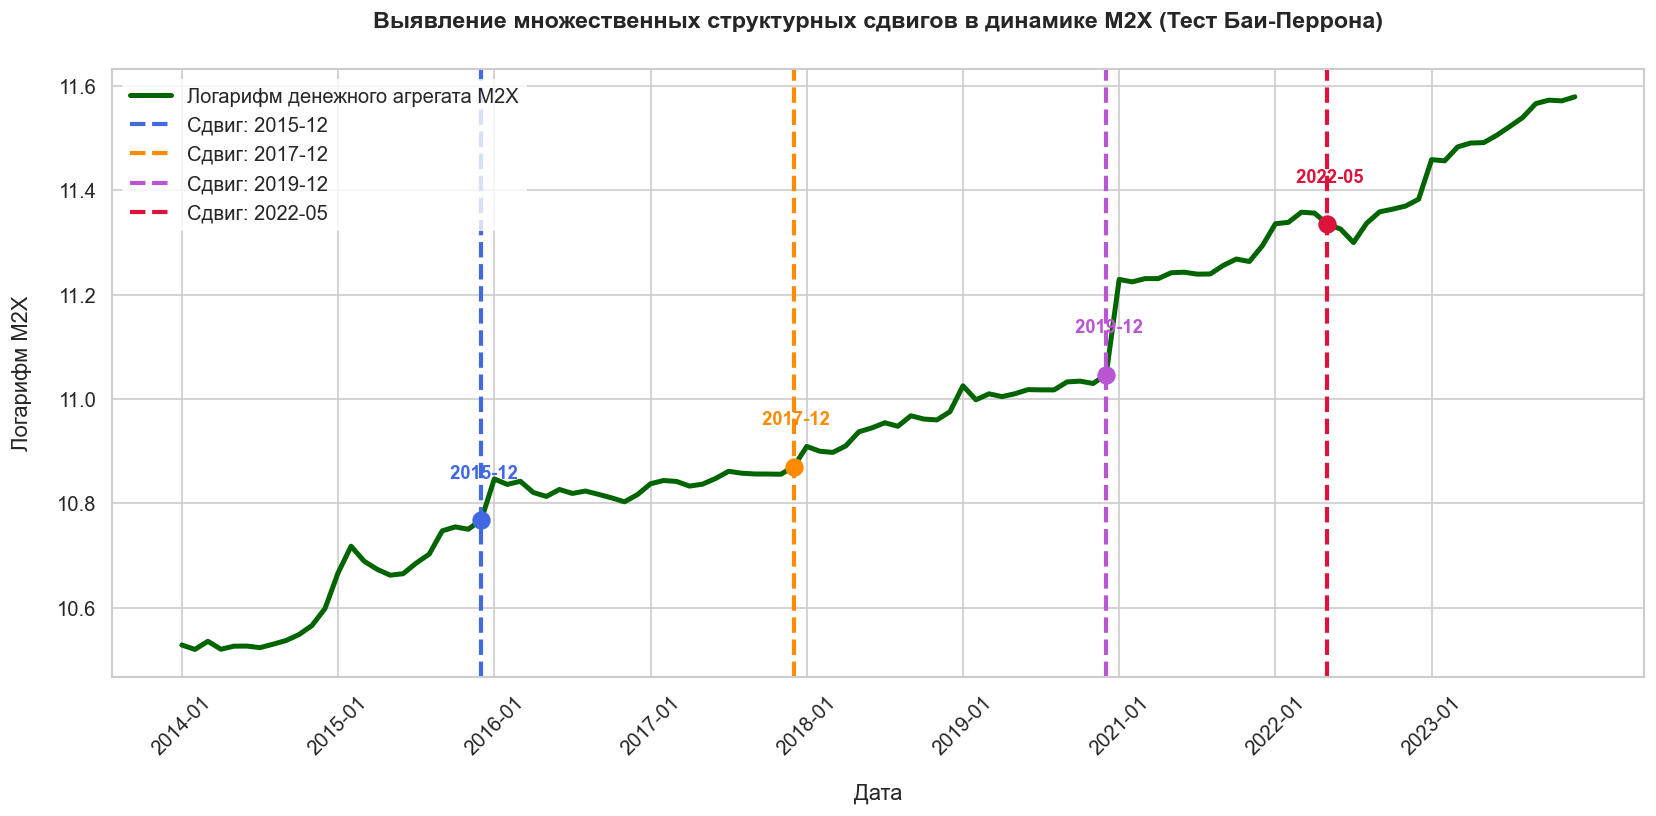

In [149]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Создаем копию и строго переводим даты в строки
df_plot = merged_df.copy()
df_plot["date"] = df_plot["date"].astype(str)

# 1. Настройка красивого стиля
sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)
plt.figure(figsize=(14, 7), dpi=120)

# 2. Основной график динамики логарифма M2X
# Напоминание: в 'growth_rate' у вас фактически лежит логарифм уровня M2X
ax = sns.lineplot(
    data=df_plot,
    x="date",
    y="growth_rate",
    color="darkgreen",  # Зеленый цвет для денежной массы
    linewidth=3,
    label="Логарифм денежного агрегата M2X",
)

# 3. Точные строковые даты сдвигов для M2X, полученные из R
break_dates_m2x = ["2015-12", "2017-12", "2019-12", "2022-05"]
colors_m2x = ["royalblue", "darkorange", "mediumorchid", "crimson"]

# 4. Расставляем вертикальные линии и подписи дат
for b_date, color in zip(break_dates_m2x, colors_m2x):
    try:
        # Извлекаем значение логарифма для конкретной даты
        break_val = df_plot[df_plot["date"] == b_date]["growth_rate"].values[0]

        # Рисуем вертикальную пунктирную линию
        plt.axvline(
            x=b_date,
            color=color,
            linestyle="--",
            linewidth=2.5,
            label=f"Сдвиг: {b_date}",
        )

        # Ставим маркер-точку на график
        plt.plot(b_date, break_val, marker="o", color=color, markersize=10)

        # Добавляем текстовую подпись
        # Смещение по y уменьшено до +0.1, так как масштаб логарифма (10.5 - 11.5) меньше, чем у ставки
        plt.text(
            x=b_date,
            y=break_val + 0.08,
            s=f" {b_date}",
            color=color,
            weight="bold",
            fontsize=11,
            horizontalalignment="center",
        )
    except IndexError:
        print(
            f"Предупреждение: Дата {b_date} не найдена в датафрейме. Проверьте формат."
        )

# 5. Красивое оформление осей и заголовков
plt.title(
    "Выявление множественных структурных сдвигов в динамике M2X (Тест Баи-Перрона)",
    pad=25,
    fontsize=14,
    weight="bold",
)
plt.xlabel("Дата", labelpad=15)
plt.ylabel("Логарифм M2X", labelpad=15)

# Настройка частоты подписей оси X (каждые 12 месяцев)
step = 12
dates_array = df_plot["date"].values
positions = np.arange(0, len(dates_array), step)
labels = [dates_array[i] for i in positions]
plt.xticks(positions, labels, rotation=45)

plt.legend(loc="upper left", frameon=True, facecolor="white", edgecolor="none")
plt.tight_layout()

# 6. Сохраняем картинку для эссе
plt.savefig("structural_breaks_m2x_bai_perron.png", bbox_inches="tight", dpi=300)
plt.show()


Шаг 6. Проверяем первую разность

1. Тест Дики-Фуллера

In [150]:
from statsmodels.tsa.stattools import adfuller

# 1. Считаем первую разность ставки и удаляем возникший NaN в первой строке
merged_df['diff_rate_M'] = merged_df['growth_rate'].diff()
diff_data_M = merged_df['diff_rate_M'].dropna()
diff_ln_M2X = diff_data_M
print("==================================================")
print("   ПОДРОБНЫЙ ADF-ТЕСТ ДЛЯ ПЕРВОЙ РАЗНОСТИ СТАВКИ  ")
print("==================================================\n")

# --- 1. ADF с константой (основной для разностей) ---
# Проверяет, стационарен ли темп изменения вокруг постоянного среднего
adf_c = adfuller(diff_data_M, regression='c')
print("--- Модель с константой (c) ---")
print(f"ADF статистика:         {adf_c[0]:.4f}")
print(f"p-value:                {adf_c[1]:.4f}")
print("Критические значения:")
for key, value in adf_c[4].items():
    print(f"   {key}: {value:.4f}")
print("-" * 30)

# --- 2. ADF без константы и тренда (дополнительный) ---
# Проверяет, стационарен ли ряд строго вокруг нуля (без дрейфа)
adf_n = adfuller(diff_data_M, regression='n')
print("--- Модель без константы и тренда (n) ---")
print(f"ADF статистика:         {adf_n[0]:.4f}")
print(f"p-value:                {adf_n[1]:.4f}")
print("Критические значения:")
for key, value in adf_n[4].items():
    print(f"   {key}: {value:.4f}")
print("-" * 30)

# --- 3. Интерпретация ---
print("\n[ИТОГОВЫЙ ВЫВОД ДЛЯ ПЕРВОЙ РАЗНОСТИ]")
# Ориентируемся на базовую модель с константой ('c')
if adf_c[1] < 0.05:
    print("→ Вывод: Первая разность СТАЦИОНАРНА (p-value < 0.05).")
    print("  Исходный ряд официально подтвержден как интегрированный первого порядка — I(1).")
    print("  Этот ряд разностей готов к использованию в модели VAR.")
else:
    print("→ Вывод: Первая разность НЕСТАЦИОНАРНА (p-value >= 0.05).")
    print("  Нулевая гипотеза о единичном корне в разностях не отвергнута.")
    print("  Ряд имеет более высокий порядок интегрируемости (d > 1).")
print("==================================================")


   ПОДРОБНЫЙ ADF-ТЕСТ ДЛЯ ПЕРВОЙ РАЗНОСТИ СТАВКИ  

--- Модель с константой (c) ---
ADF статистика:         -2.2544
p-value:                0.1871
Критические значения:
   1%: -3.5011
   5%: -2.8925
   10%: -2.5833
------------------------------
--- Модель без константы и тренда (n) ---
ADF статистика:         -1.0523
p-value:                0.2636
Критические значения:
   1%: -2.5897
   5%: -1.9442
   10%: -1.6143
------------------------------

[ИТОГОВЫЙ ВЫВОД ДЛЯ ПЕРВОЙ РАЗНОСТИ]
→ Вывод: Первая разность НЕСТАЦИОНАРНА (p-value >= 0.05).
  Нулевая гипотеза о единичном корне в разностях не отвергнута.
  Ряд имеет более высокий порядок интегрируемости (d > 1).


2. Тест Филлипса-Перрона

In [151]:
from arch.unitroot import PhillipsPerron

pp_test = PhillipsPerron(diff_data_M)
print(pp_test)
# Если p-value < 0.05, ряд стационарный. 

     Phillips-Perron Test (Z-tau)    
Test Statistic                -10.145
P-value                         0.000
Lags                               13
-------------------------------------

Trend: Constant
Critical Values: -3.49 (1%), -2.89 (5%), -2.58 (10%)
Null Hypothesis: The process contains a unit root.
Alternative Hypothesis: The process is weakly stationary.


3. KPSS

In [152]:
from statsmodels.tsa.stattools import kpss

# KPSS с трендом (для проверки TS)
kpss_ct = kpss(diff_data_M, regression='ct')
print(f'KPSS (с трендом): p-value = {kpss_ct[1]:.4f}')

if kpss_ct[1] < 0.05:
    print("→ KPSS: отвергаем стационарность → ряд нестационарен")
else:
    print("→ KPSS: не отвергаем стационарность → ряд стационарен")

KPSS (с трендом): p-value = 0.1000
→ KPSS: не отвергаем стационарность → ряд стационарен


Шаг 7. Визуализируем первую разность

Первая разность

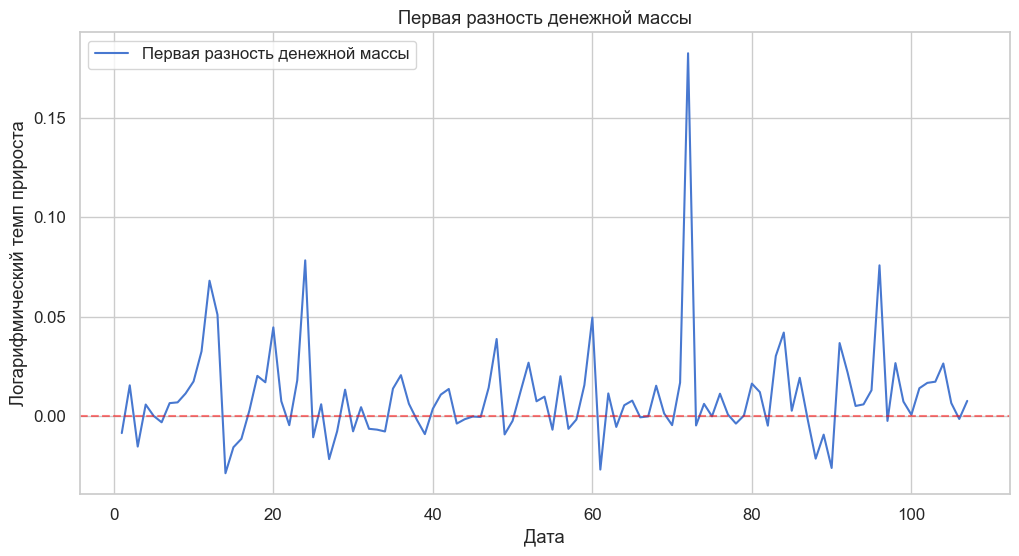

In [153]:
plt.figure(figsize=(12, 6))
plt.plot(diff_ln_M2X, label='Первая разность денежной массы')
plt.axhline(y=0, color='red', linestyle='--', alpha=0.5)
plt.title('Первая разность денежной массы')
plt.xlabel('Дата')
plt.ylabel('Логарифмический темп прироста')
plt.legend()
plt.grid(True)
plt.show()

Коррелограммы

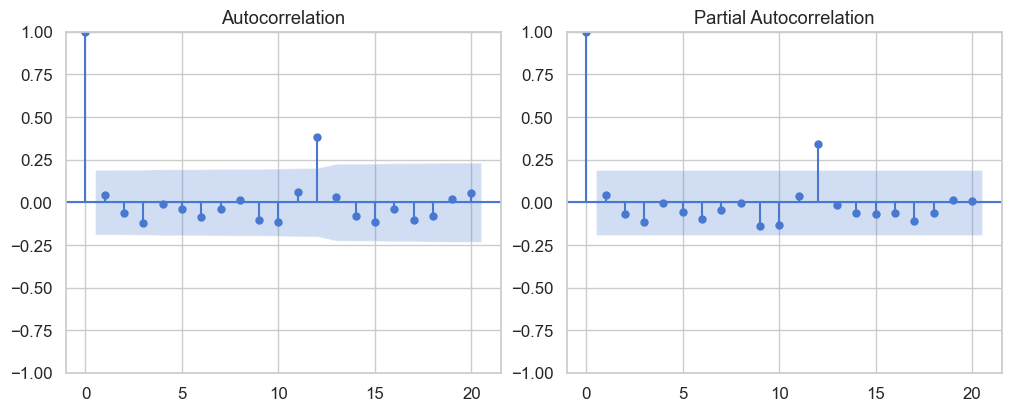

In [154]:
fig, [ax1,ax2] = plt.subplots(nrows = 1, ncols = 2, figsize = (10, 4), constrained_layout=True)

sm.graphics.tsa.plot_acf(diff_ln_M2X, ax=ax1, lags=20)
sm.graphics.tsa.plot_pacf(diff_ln_M2X, ax=ax2, method='ywm', lags=20)
plt.show()

Шаг 8. Проводим HEGY-тест в R. Он показал наличие сезонного единичного корня, следовательно, D=1

Шаг 9. Подбор модели

Автоподбор

In [155]:
# Подбор оптимальных параметров (p, d, q) с auto_arima
import pmdarima as pm
model_auto = pm.auto_arima(merged_df['growth_rate'], seasonal=True, stepwise=True, trace=True)
print(model_auto.summary())

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=-478.560, Time=0.44 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=-480.557, Time=0.03 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=-478.744, Time=0.03 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=-478.770, Time=0.07 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=-467.375, Time=0.04 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=-476.666, Time=0.06 sec

Best model:  ARIMA(0,1,0)(0,0,0)[0] intercept
Total fit time: 0.686 seconds
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  108
Model:               SARIMAX(0, 1, 0)   Log Likelihood                 242.279
Date:                Thu, 28 May 2026   AIC                           -480.557
Time:                        14:56:42   BIC                           -475.211
Sample:                             0   HQIC                          -478.390
          

Перебираем параметры и выбираем лучшую модель по критерию Акаике

In [156]:
import pandas as pd
import statsmodels.api as sm

# Словарь с конфигурациями моделей: (p, d, q, P, D, Q, s)
models_specs = {
    "model_01 (0,1,0)x(1,1,0)12": (0, 1, 0, 1, 1, 0, 12),
    "model_02 (0,1,0)x(0,1,1)12": (0, 1, 0, 0, 1, 1, 12),
    "model_03 (0,1,0)x(1,1,1)12": (0, 1, 0, 1, 1, 1, 12),
    "model_04 (1,1,0)x(1,1,0)12": (1, 1, 0, 1, 1, 0, 12),
    "model_05 (1,1,0)x(0,1,1)12": (1, 1, 0, 0, 1, 1, 12),
    "model_06 (1,1,0)x(1,1,1)12": (1, 1, 0, 1, 1, 1, 12),
    "model_07 (0,1,1)x(1,1,0)12": (0, 1, 1, 1, 1, 0, 12),
    "model_08 (0,1,1)x(0,1,1)12": (0, 1, 1, 0, 1, 1, 12),
    "model_09 (0,1,1)x(1,1,1)12": (0, 1, 1, 1, 1, 1, 12),
    "model_10 (1,1,1)x(1,1,0)12": (1, 1, 1, 1, 1, 0, 12),
    "model_11 (1,1,1)x(0,1,1)12": (1, 1, 1, 0, 1, 1, 12),
    "model_12 (1,1,1)x(1,1,1)12": (1, 1, 1, 1, 1, 1, 12),
}

results_list = []

# Цикл обучения моделей и сбора AIC
for name, spec in models_specs.items():
    try:
        # Инициализируем модель по спецификации
        model = sm.tsa.ARIMA(
            merged_df["growth_rate"],
            order=(spec[0], spec[1], spec[2]),
            seasonal_order=(spec[3], spec[4], spec[5], spec[6]),
        )
        # Обучаем модель
        fitted_model = model.fit()

        # Сохраняем имя и результат AIC
        results_list.append({"Модель": name, "AIC": round(fitted_model.aic, 2)})
    except Exception as e:
        # Пропускаем комбинации, если возникнет ошибка сходимости алгоритма
        print(f"Ошибка при расчете {name}: {e}")
        continue

# Переводим в датафрейм и сортируем по возрастанию AIC (меньше = лучше)
aic_df = pd.DataFrame(results_list).sort_values(by="AIC", ascending=True)

# Выводим итоговую таблицу
print("\n=== Результаты сравнения моделей по AIC ===")
print(aic_df.to_string(index=False))



=== Результаты сравнения моделей по AIC ===
                    Модель     AIC
model_02 (0,1,0)x(0,1,1)12 -458.19
model_03 (0,1,0)x(1,1,1)12 -456.40
model_08 (0,1,1)x(0,1,1)12 -456.28
model_05 (1,1,0)x(0,1,1)12 -456.27
model_06 (1,1,0)x(1,1,1)12 -454.47
model_09 (0,1,1)x(1,1,1)12 -454.25
model_11 (1,1,1)x(0,1,1)12 -453.11
model_12 (1,1,1)x(1,1,1)12 -452.42
model_01 (0,1,0)x(1,1,0)12 -440.04
model_04 (1,1,0)x(1,1,0)12 -438.12
model_07 (0,1,1)x(1,1,0)12 -438.11
model_10 (1,1,1)x(1,1,0)12 -436.10


=> лучшая model_02

Обучаем лучшую модель

In [211]:
import pandas as pd
import numpy as np
import statsmodels.api as sm

# 1. Принудительно даты в строки
merged_df['date_str'] = merged_df['date'].astype(str)

# 2. Создаем ровно 3 ТОЧЕЧНЫХ (импульсных) дамми-переменных
dummy_shock_15 = pd.Series(0, index=merged_df.index, dtype=int)
dummy_shock_19 = pd.Series(0, index=merged_df.index, dtype=int)
dummy_shock_22 = pd.Series(0, index=merged_df.index, dtype=int)

# Находим ОДИН конкретный месяц максимального шока для каждого периода
# Вы можете скорректировать месяцы (например, '2015-01', '2022-03' - в зависимости от того, где пик на графике)
idx_15 = merged_df[merged_df['date_str'].str.startswith('2015-12')].index
idx_19 = merged_df[merged_df['date_str'].str.startswith('2019-12')].index
idx_22 = merged_df[merged_df['date_str'].str.startswith('2022-05')].index # март 2022 - пик шока ставки и ликвидности

# Ставим единицу СТРОГО в одну эту точку (в один месяц)
if len(idx_15) > 0: dummy_shock_15.loc[idx_15] = 1
if len(idx_19) > 0: dummy_shock_19.loc[idx_19] = 1
if len(idx_22) > 0: dummy_shock_22.loc[idx_22] = 1

# 3. Собираем строго 3 экзогенные переменные (мультиколлинеарность невозможна!)
exog_pulse = pd.DataFrame({
    'dummy_2015': dummy_shock_15,
    'dummy_2019': dummy_shock_19,
    'dummy_2022': dummy_shock_22
})

# 4. Обучаем модель
endog_m2 = merged_df['growth_rate']
result_pulse = sm.tsa.ARIMA(
    endog_m2, 
    order=(0, 1, 0), 
    seasonal_order=(0, 1, 1, 12), 
    exog=exog_pulse
).fit()

print(result_pulse.summary())


                                     SARIMAX Results                                      
Dep. Variable:                        growth_rate   No. Observations:                  108
Model:             ARIMA(0, 1, 0)x(0, 1, [1], 12)   Log Likelihood                 243.998
Date:                            Thu, 28 May 2026   AIC                           -477.997
Time:                                    15:21:32   BIC                           -465.227
Sample:                                         0   HQIC                          -472.837
                                            - 108                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
dummy_2015    -0.0144      0.015     -0.983      0.325      -0.043       0.014
dummy_2019    -0.0664      0.004   

Шаг 10. Проверяем остатки. Проводим критерий Льюнг-Бокса

     lb_stat  lb_pvalue
11  0.009117        1.0


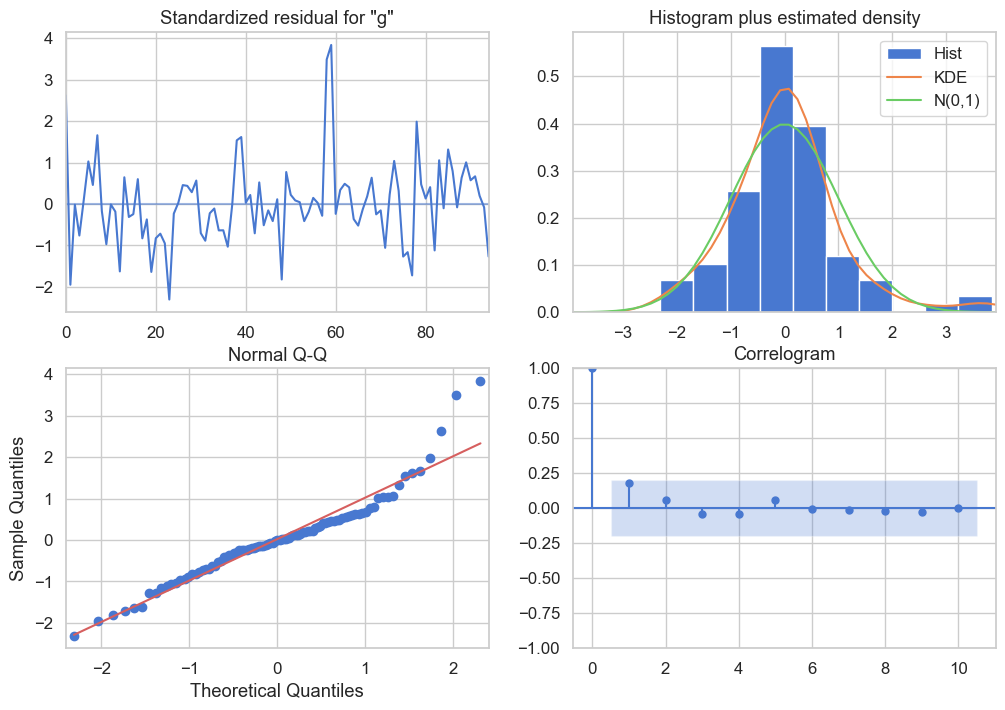

In [215]:
from statsmodels.stats.diagnostic import acorr_ljungbox
lb_test = acorr_ljungbox(result_pulse.resid, lags=[11], return_df=True)
print(lb_test) #Интерпретируйте результат (например: "p-value > 0.05 → остатки белые шумы").
result_pulse.plot_diagnostics(figsize=(12, 8))
plt.show()

Шаг 11. Тест Харке-Бера

In [210]:
from scipy.stats import jarque_bera
from statsmodels.stats.diagnostic import het_arch


residuals = result_pulse.resid
jb_stat, jb_pvalue = jarque_bera(residuals)

print("=" * 50)
print("ТЕСТ ЖАРКА–БЕРА (нормальность остатков)")
print("=" * 50)
print(f"Статистика Жарка–Бера: {jb_stat:.4f}")
print(f"p-value: {jb_pvalue:.6f}")
print()

if jb_pvalue > 0.05:
    print("→ p-value > 0.05 → H₀ не отвергается")
    print("→ Распределение остатков НЕ отличается от нормального")
else:
    print("→ p-value < 0.05 → H₀ отвергается")
    print("→ Распределение остатков ОТЛИЧАЕТСЯ от нормального")

ТЕСТ ЖАРКА–БЕРА (нормальность остатков)
Статистика Жарка–Бера: 22847.6126
p-value: 0.000000

→ p-value < 0.05 → H₀ отвергается
→ Распределение остатков ОТЛИЧАЕТСЯ от нормального


Шаг 12. Тест Шапиро-Уилка

In [201]:
import scipy.stats as stats

# Функция возвращает статистику W и p-value
sw_stat, sw_p_value = stats.shapiro(residuals)

print("--- Результаты теста Шапиро-Уилка ---")
print(f"Статистика теста W   : {sw_stat:.3f}")
print(f"p-value              : {sw_p_value:.6f}")

if sw_p_value < 0.05:
    print("Вывод: p-value < 0.05. Отвергаем нулевую гипотезу о нормальности.")
else:
    print("Вывод: p-value >= 0.05. Остатки распределены нормально.")
print("=========================================================")


--- Результаты теста Шапиро-Уилка ---
Статистика теста W   : 0.137
p-value              : 0.000000
Вывод: p-value < 0.05. Отвергаем нулевую гипотезу о нормальности.


Шаг 13. ARCH-LM тест

In [202]:
import numpy as np
from statsmodels.stats.diagnostic import het_arch

# 1. Извлекаем чистые остатки модели (убираем первый NaN из-за d=1)


print("=========================================================")
print("        ARCH-LM ТЕСТ ЭНГЕЛЯ НА ГЕТЕРОСКЕДАСТИЧНОСТЬ       ")
print("=========================================================\n")

# 2. Запускаем тест ARCH-LM
#nlags=4 означает, что мы проверяем условную гетероскедастичность до 4 лага включительно
arch_test_res = het_arch(residuals, nlags=4)

# Функция возвращает 4 значения: LM-статистику, её p-value, F-статистику и её p-value
lm_stat, lm_p_val, f_stat, f_p_val = arch_test_res

print(f"LM-статистика теста    : {lm_stat:.3f}")
print(f"p-value (LM-test)      : {lm_p_val:.6f}")
print(f"F-статистика теста    : {f_stat:.3f}")
print(f"p-value (F-test)       : {f_p_val:.6f}")
print("---------------------------------------------------------")

if lm_p_val < 0.05:
    print("Вывод: p-value < 0.05. Отвергаем нулевую гипотезу.")
    print("→ В остатках ПРИСУТСТВУЮТ ARCH-эффекты (гетероскедастичность).")
    print("→ Рекомендация для эссе: требуется построение моделей ARCH/GARCH.")
else:
    print("Вывод: p-value >= 0.05. Нет оснований отвергать нулевую гипотезу.")
    print("→ ARCH-эффекты отсутствуют, дисперсия остатков гомоскедастична.")
print("=========================================================")


        ARCH-LM ТЕСТ ЭНГЕЛЯ НА ГЕТЕРОСКЕДАСТИЧНОСТЬ       

LM-статистика теста    : 0.045
p-value (LM-test)      : 0.999752
F-статистика теста    : 0.011
p-value (F-test)       : 0.999770
---------------------------------------------------------
Вывод: p-value >= 0.05. Нет оснований отвергать нулевую гипотезу.
→ ARCH-эффекты отсутствуют, дисперсия остатков гомоскедастична.


Шаг 14. Прогнозирование

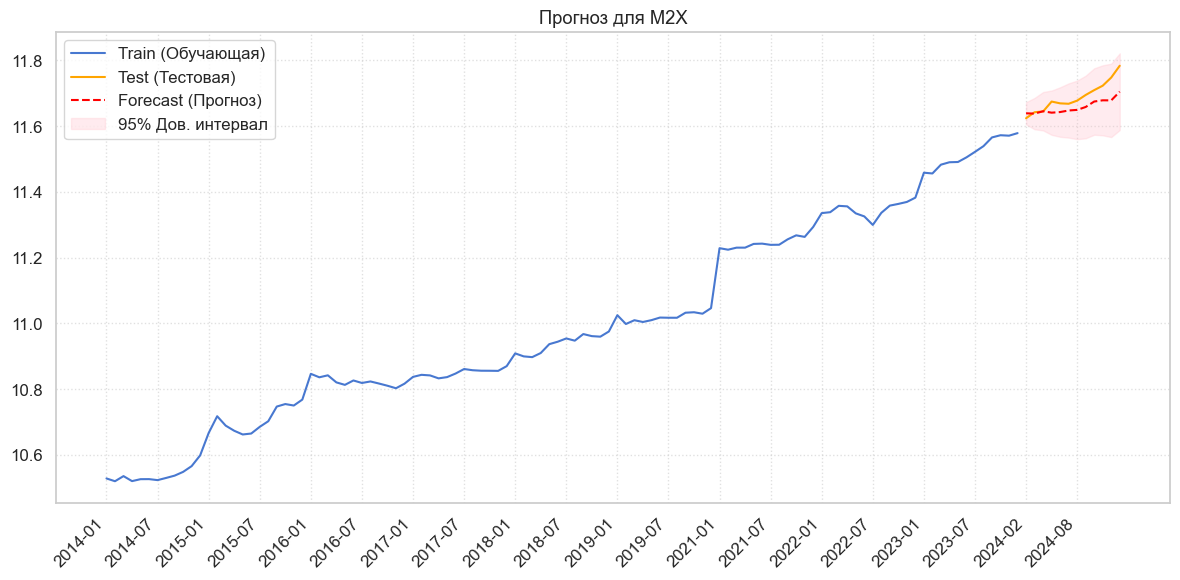

In [214]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Формируем exog для тестовой выборки (всегда нули для импульсных дамми в будущем)
forecast_steps = len(M_2_X_test)
exog_forecast = pd.DataFrame(0, index=M_2_X_test.index, columns=['pulse_2015', 'pulse_2019', 'pulse_2022'])

# 2. Прогнозирование с обязательным указанием exog
forecast = result_pulse.get_forecast(steps=forecast_steps, exog=exog_forecast)
forecast_mean = forecast.predicted_mean
forecast_ci = forecast.conf_int()

# Выравниваем индексы прогноза с тестовыми датами для корректного построения графиков
forecast_mean.index = M_2_X_test.index
forecast_ci.index = M_2_X_test.index

# 3. Визуализация прогноза
plt.figure(figsize=(12, 6))
plt.plot(merged_df['date'], merged_df['growth_rate'], label='Train (Обучающая)')
plt.plot(M_2_X_test['date'], M_2_X_test['growth_rate'], label='Test (Тестовая)', color='orange')
plt.plot(M_2_X_test['date'], forecast_mean, label='Forecast (Прогноз)', color='red', linestyle='--')

# Доверительный интервал
plt.fill_between(M_2_X_test['date'],
                 forecast_ci.iloc[:, 0],
                 forecast_ci.iloc[:, 1],
                 color='pink', alpha=0.3, label='95% Дов. интервал')

# 4. Исправление настройки оси X (работаем напрямую с объектами дат)
all_dates = pd.concat([merged_df['date'], M_2_X_test['date']]).reset_index(drop=True)

# Берем каждую 6-ю дату из реального массива дат
unique_ticks = all_dates.iloc[::6] 

# Передаем реальные даты и в ticks, и в labels (чтобы избежать смещения графиков)
plt.xticks(ticks=unique_ticks, labels=unique_ticks.astype(str), rotation=45, ha='right')

plt.title('Прогноз для М2Х')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


Шаг 15. Ошибки прогноза и расчёт метрик

Средняя абсолютная процентная ошибка (MAPE): 0.28%

Сравнение прогноза с реальными значениями:
   Date    Actual  Forecast     Error
2024-02 11.624262 11.639239 -0.014977
2024-03 11.642589 11.638420  0.004169
2024-04 11.644880 11.645609 -0.000730
2024-05 11.675018 11.641203  0.033815
2024-06 11.669580 11.643147  0.026433
2024-07 11.668297 11.647829  0.020468
2024-08 11.677879 11.649685  0.028194
2024-09 11.695060 11.658534  0.036526
2024-10 11.709801 11.675127  0.034675
2024-11 11.723246 11.678819  0.044427
2024-12 11.748092 11.678604  0.069489
2025-01 11.784008 11.705129  0.078879


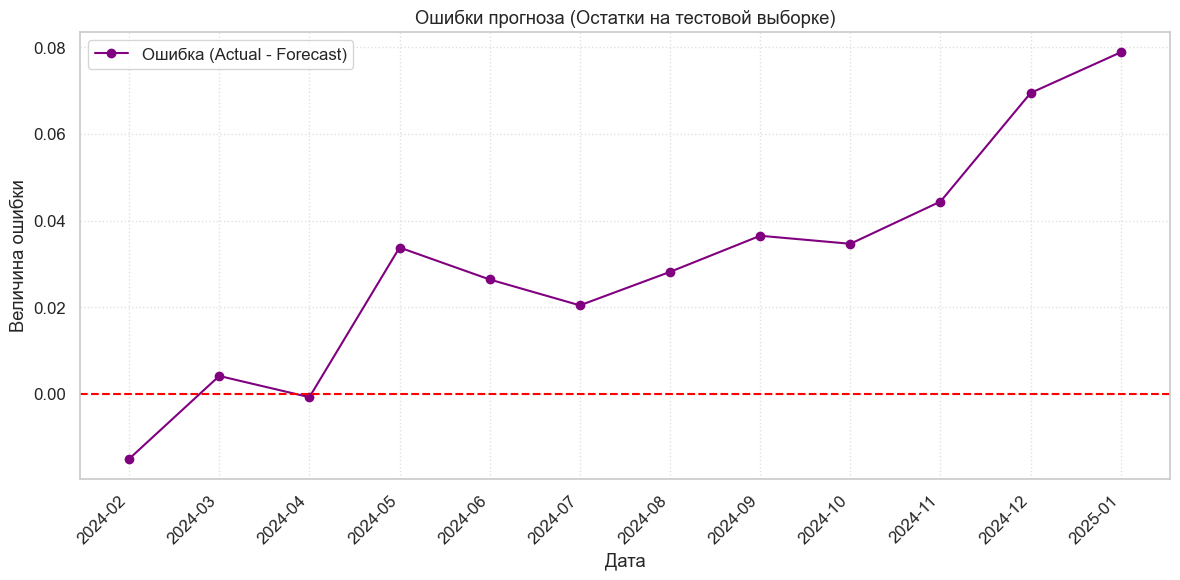

In [207]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_percentage_error

# 1. Расчет количества шагов прогноза
forecast_steps = len(M_2_X_test)

# 2. ИСПРАВЛЕНИЕ: Обязательно создаем нулевую матрицу дамми для тестового периода
exog_forecast = pd.DataFrame(0, index=M_2_X_test.index, columns=['pulse_2015', 'pulse_2019', 'pulse_2022'])

# 3. ИСПРАВЛЕНИЕ: Передаем exog в get_forecast
forecast = result_pulse.get_forecast(steps=forecast_steps, exog=exog_forecast)
forecast_mean = forecast.predicted_mean

# Выравниваем индексы прогноза с тестовыми данными
forecast_mean.index = M_2_X_test.index

# 4. Расчет ошибок прогноза (теперь mape посчитается без ошибок)
mape = mean_absolute_percentage_error(M_2_X_test['growth_rate'], forecast_mean) * 100
print(f"Средняя абсолютная процентная ошибка (MAPE): {mape:.2f}%")

# 5. Анализ точности прогноза
comparison = pd.DataFrame({
    'Date': M_2_X_test['date'],  # Добавляем столбец с датами для наглядности
    'Actual': M_2_X_test['growth_rate'],
    'Forecast': forecast_mean,
    'Error': M_2_X_test['growth_rate'] - forecast_mean
})
print("\nСравнение прогноза с реальными значениями:")
print(comparison.to_string(index=False))  # Выводим без системных индексов

# 6. График ошибок прогноза с красивой осью X
plt.figure(figsize=(12, 6))

# ИСПРАВЛЕНИЕ: Строим график ошибок, явно привязывая его к реальным датам
plt.plot(comparison['Date'], comparison['Error'], color='purple', marker='o', label='Ошибка (Actual - Forecast)')
plt.axhline(0, color='red', linestyle='--')

# Настраиваем подписи оси X (поворачиваем даты, чтобы они не перекрывали друг друга)
plt.xticks(rotation=45, ha='right')

plt.title('Ошибки прогноза (Остатки на тестовой выборке)')
plt.ylabel('Величина ошибки')
plt.xlabel('Дата')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


In [165]:
def smape(y_true, y_pred):
    return 100 * np.mean(2 * np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred)))

print(f"SMAPE: {smape(M_2_X_test['growth_rate'], forecast_mean):.2f}%")


SMAPE: 0.25%


# Коинтеграция

Кажется, этого нет

Посмотрим на график

In [166]:
merged_df

,date,rate,growth_rate,diff_rate,date_str,diff_rate_M
0,2014-01,5.5,10.528589,NaN,2014-01,NaN
1,2014-02,5.5,10.520145,0.0,2014-02,-0.008444
2,2014-03,7.0,10.535692,1.5,2014-03,0.015547
3,2014-04,7.5,10.520480,0.5,2014-04,-0.015213
4,2014-05,7.5,10.526379,0.0,2014-05,0.005899
...,...,...,...,...,...,...
103,2023-08,12.0,11.539439,3.5,2023-08,0.017369
104,2023-09,13.0,11.565956,1.0,2023-09,0.026517
105,2023-10,15.0,11.572602,2.0,2023-10,0.006646
106,2023-11,15.0,11.571242,0.0,2023-11,-0.001359


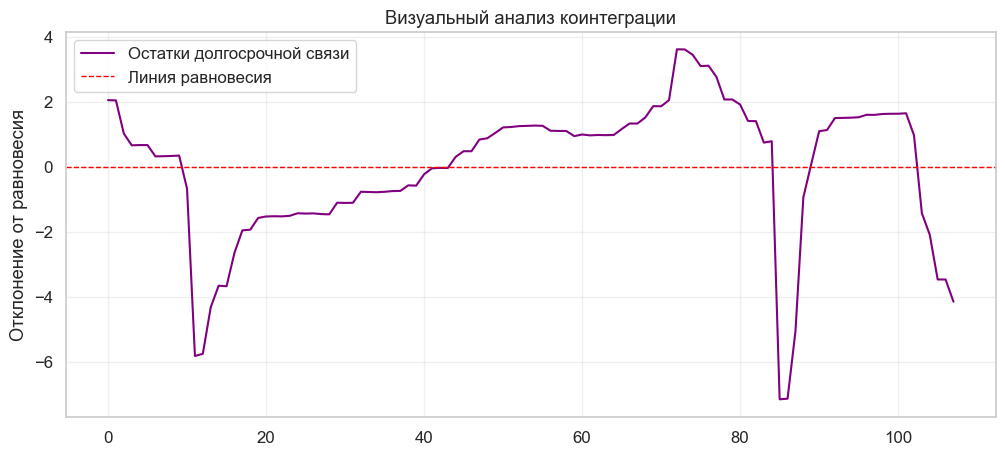

In [167]:
import matplotlib.pyplot as plt

# Считаем чистую комбинацию без учета константы Йохансена
# (если ставка записана как 16.0, а не 0.16, делить на 100 не нужно)
merged_df['coint_comb'] = merged_df['growth_rate'] - 69.08411 * (merged_df['rate'] / 100)

# Центрируем ряд вокруг нуля (вычитаем среднее), чтобы убрать проблему масштаба константы
merged_df['coint_residuals_fixed'] = merged_df['coint_comb'] - merged_df['coint_comb'].mean()

# Строим график
plt.figure(figsize=(12, 5))
plt.plot(merged_df['coint_residuals_fixed'], color='purple', linewidth=1.5, label='Остатки долгосрочной связи')
plt.axhline(0, color='red', linestyle='--', linewidth=1, label='Линия равновесия ')

plt.title('Визуальный анализ коинтеграции')

plt.ylabel('Отклонение от равновесия')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


Чтобы на верняка проверяем различные тесты

In [168]:
import statsmodels.tsa.stattools as ts

# Подготавливаем переменные (rate делим на 100, как в вашей формуле)
y = merged_df['growth_rate']
x = merged_df['rate'] / 100

# Запуск теста Энгла-Грэнджера
# trend='c' означает, что в уравнение коинтеграции включается константа
coint_t, p_value, crit_value = ts.coint(y, x, trend='c')

print("--- Тест Энгла-Грэнджера ---")
print(f"t-статистика: {coint_t:.4f}")
print(f"p-value: {p_value:.4f}")
print(f"Критические значения (1%, 5%, 10%): {crit_value}")

if p_value < 0.05:
    print("Результат: Нулевая гипотеза отвергается. Коинтеграция ЕСТЬ.")
else:
    print("Результат: Нулевая гипотеза НЕ отвергается. Коинтеграции НЕТ.")


--- Тест Энгла-Грэнджера ---
t-статистика: 0.4023
p-value: 0.9919
Критические значения (1%, 5%, 10%): [-4.00172258 -3.39382969 -3.08432496]
Результат: Нулевая гипотеза НЕ отвергается. Коинтеграции НЕТ.


In [169]:
from statsmodels.tsa.stattools import kpss

# Берем ваши очищенные остатки
residuals = merged_df['coint_residuals_fixed']

# Запуск теста KPSS (regression='c' — стационарность вокруг константы, которая у вас 0)
kpss_stat, p_value, lags, crit_values = kpss(residuals, regression='c')

print("--- Тест KPSS на остатки ---")
print(f"KPSS Статистика: {kpss_stat:.4f}")
print(f"p-value: {p_value:.4f}")
print(f"Критические значения: {crit_values}")

# ВНИМАНИЕ: Здесь логика p-value обратная!
if p_value > 0.05:
    print("Результат: Нулевая гипотеза НЕ отвергается. Остатки стационарны -> Коинтеграция ЕСТЬ.")
else:
    print("Результат: Нулевая гипотеза отвергается. Остатки НЕстационарны -> Коинтеграции НЕТ.")


--- Тест KPSS на остатки ---
KPSS Статистика: 0.3402
p-value: 0.1000
Критические значения: {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}
Результат: Нулевая гипотеза НЕ отвергается. Остатки стационарны -> Коинтеграция ЕСТЬ.


In [170]:
# Если библиотека не установлена, раскомментируйте строку ниже:
# !pip install arch

from arch.unitroot.cointegration import phillips_ouliaris

# Запуск теста (включаем константу 'c')
po_test = phillips_ouliaris(merged_df['growth_rate'], merged_df['rate'] / 100, trend='c')

print("--- Тест Филлипса — Улиара ---")
print(po_test.summary())

if po_test.pvalue < 0.05:
    print("\nРезультат: Коинтеграция ЕСТЬ.")
else:
    print("\nРезультат: Коинтеграции НЕТ.")


--- Тест Филлипса — Улиара ---
Phillips-Ouliaris Zt Cointegration Test
Test Statistic                 -0.050
P-value                         0.997
Kernel                       Bartlett
Bandwidth                       6.491
-------------------------------------

Trend: Constant
Critical Values: -3.11 (10%), -3.43 (5%), -4.04 (1%)
Null Hypothesis: No Cointegration
Alternative Hypothesis: Cointegration
Distribution Order: 3

Результат: Коинтеграции НЕТ.


Тест Йоханса - если что есть ещё в R

In [171]:
import numpy as np
import pandas as pd
from statsmodels.tsa.vector_ar.vecm import coint_johansen

# 1. Подготовка матрицы данных (две переменные)
data_matrix = merged_df[['growth_rate', 'rate']].dropna().copy()
data_matrix['rate'] = data_matrix['rate'] / 100

# 2. Запуск теста Йохансена
# det_order = 0  -> только константа
# k_ar_diff = 1  -> 1 лаг в разностях (в R задавайте K = 2)
johansen_res = coint_johansen(data_matrix, det_order=0, k_ar_diff=1)

# 3. Вывод результатов (строка с ошибкой удалена)
print("--- ТЕСТ ЙОХАНСЕНА (PYTHON) ---")
print("Элементы (Переменные): growth_rate, rate / 100\n")

print("Гипотеза | След (Trace Stat) | Крит. значение (5%)")
print("-" * 50)
for i in range(len(johansen_res.lr1)):
    # Нулевая гипотеза: ранг матрицы <= i
    print(f"r <= {i}    | {johansen_res.lr1[i]:.4f}           | {johansen_res.cvt[i, 1]:.4f}")

print("\nГипотеза | Макс. Собств. (Max Eigen) | Крит. значение (5%)")
print("-" * 55)
for i in range(len(johansen_res.lr2)):
    print(f"r == {i}    | {johansen_res.lr2[i]:.4f}               | {johansen_res.cvm[i, 1]:.4f}")


--- ТЕСТ ЙОХАНСЕНА (PYTHON) ---
Элементы (Переменные): growth_rate, rate / 100

Гипотеза | След (Trace Stat) | Крит. значение (5%)
--------------------------------------------------
r <= 0    | 12.5489           | 15.4943
r <= 1    | 0.0004           | 3.8415

Гипотеза | Макс. Собств. (Max Eigen) | Крит. значение (5%)
-------------------------------------------------------
r == 0    | 12.5485               | 14.2639
r == 1    | 0.0004               | 3.8415


In [172]:
from statsmodels.tsa.vector_ar.vecm import coint_johansen

# Передаем исходную ставку (НЕ делим на 100) и логарифм данных
# det_order = 1: говорит модели, что у денежной массы есть долгосрочный восходящий тренд
# k_ar_diff = 1 (или 2): количество лагов
johansen_test = coint_johansen(merged_df[['rate', 'growth_rate']], det_order=1, k_ar_diff=1)

# Выводим след (Trace)
print("Trace Stat:", johansen_test.lr1)
print("Critical Values (95%):", johansen_test.cvt[:, 1])


Trace Stat: [23.78859324  6.29469115]
Critical Values (95%): [18.3985  3.8415]


# VAR

шаг 1. Подготовка данных для векторной авторегрессии. Работем только с первыми разностями

In [173]:
import pandas as pd
from statsmodels.tsa.api import VAR

# Создаем датафрейм из первых разностей
var_data = pd.DataFrame({
    'd_growth_rate': merged_df['growth_rate'].diff(), # Изменение темпа М2Х
    'd_rate': merged_df['rate'].diff()                # Изменение ставки ЦБ
}).dropna().reset_index(drop=True)


Шаг 2. Проверяем стационарность

1. Тест Дики-Фуллера

In [174]:
import pandas as pd
from statsmodels.tsa.stattools import adfuller

# Создаем датафрейм из первых разностей
diff_df = pd.DataFrame({
    'd_rate': merged_df['rate'].astype(float).diff(),
    'd_growth_rate': merged_df['growth_rate'].astype(float).diff()
}).dropna().reset_index(drop=True)

print("==========================================================================")
print("             1. РЕЗУЛЬТАТЫ ТЕСТА ДИКИ-ФУЛЛЕРА (ADF) FOR LAGS              ")
print("==========================================================================")
print(f"{'Переменная':<25}{'Статистика':<15}{'p-value':<12}{'Крит. значение (5%)'}")
print("-" * 74)

for col, name in [('d_rate', 'Δrate (Ставка)'), ('d_growth_rate', 'Δgrowth_rate (M2X)')]:
    res = adfuller(diff_df[col], regression='c')
    print(f"{name:<25}{res[0]:<15.4f}{res[1]:<12.4f}{res[4]['5%']:.4f}")

print("-" * 74)
print("[ВЫВОД ДЛЯ ЭССЕ]:")
print("Для стационарности p-value должен быть < 0.05, а статистика меньше критического значения.")
print("Если условия выполнены, нулевая гипотеза о единичном корне отвергается, ряд стационарен I(0).")
print("==========================================================================\n")


             1. РЕЗУЛЬТАТЫ ТЕСТА ДИКИ-ФУЛЛЕРА (ADF) FOR LAGS              
Переменная               Статистика     p-value     Крит. значение (5%)
--------------------------------------------------------------------------
Δrate (Ставка)           -7.0528        0.0000      -2.8898
Δgrowth_rate (M2X)       -2.2544        0.1871      -2.8925
--------------------------------------------------------------------------
[ВЫВОД ДЛЯ ЭССЕ]:
Для стационарности p-value должен быть < 0.05, а статистика меньше критического значения.
Если условия выполнены, нулевая гипотеза о единичном корне отвергается, ряд стационарен I(0).



2. Тест Филлипса-Перрона

In [175]:
from arch.unitroot import PhillipsPerron

print("==========================================================================")
print("             2. РЕЗУЛЬТАТЫ ТЕСТА ФИЛЛИПСА-ПЕРРОНА (PP)                    ")
print("==========================================================================")
print(f"{'Переменная':<25}{'Статистика':<15}{'p-value':<12}{'Крит. значение (5%)'}")
print("-" * 74)

for col, name in [('d_rate', 'Δrate (Ставка)'), ('d_growth_rate', 'Δgrowth_rate (M2X)')]:
    res = PhillipsPerron(diff_df[col], trend='c')
    print(f"{name:<25}{res.stat:<15.4f}{res.pvalue:<12.4f}{res.critical_values['5%']:.4f}")

print("-" * 74)
print("[ВЫВОД ДЛЯ ЭССЕ]:")
print("Тест PP более устойчив к макроэкономическим шокам и гетероскедастичности.")
print("При p-value < 0.05 нулевая гипотеза о наличии единичного корня уверенно отвергается.")
print("==========================================================================\n")


             2. РЕЗУЛЬТАТЫ ТЕСТА ФИЛЛИПСА-ПЕРРОНА (PP)                    
Переменная               Статистика     p-value     Крит. значение (5%)
--------------------------------------------------------------------------
Δrate (Ставка)           -8.2058        0.0000      -2.8892
Δgrowth_rate (M2X)       -10.1451       0.0000      -2.8892
--------------------------------------------------------------------------
[ВЫВОД ДЛЯ ЭССЕ]:
Тест PP более устойчив к макроэкономическим шокам и гетероскедастичности.
При p-value < 0.05 нулевая гипотеза о наличии единичного корня уверенно отвергается.



3. KPSS

In [176]:
from statsmodels.tsa.stattools import kpss
import warnings
 # подавляем технические предупреждения пакета

print("==========================================================================")
print("             3. РЕЗУЛЬТАТЫ ТЕСТА KPSS (H0 = СТАЦИОНАРЕН)                 ")
print("==========================================================================")
print(f"{'Переменная':<25}{'Статистика':<15}{'p-value':<12}{'Крит. значение (5%)'}")
print("-" * 74)

for col, name in [('d_rate', 'Δrate (Ставка)'), ('d_growth_rate', 'Δgrowth_rate (M2X)')]:
    res = kpss(diff_df[col], regression='c', nlags="auto")
    print(f"{name:<25}{res[0]:<15.4f}{res[1]:<12.4f}{res[3]['5%']:.4f}")

print("-" * 74)
print("[ВЫВОД ДЛЯ ЭССЕ] — ВНИМАНИЕ:")
print("В тесте KPSS нулевая гипотеза (H0) утверждает, что ряд СТАЦИОНАРЕН.")
print("Поэтому для подтверждения стационарности нам нужно, чтобы p-value был БОЛЬШЕ 0.05,")
print("а статистика была МЕНЬШЕ критического значения (гипотеза о стационарности НЕ отвергается).")
print("==========================================================================\n")


             3. РЕЗУЛЬТАТЫ ТЕСТА KPSS (H0 = СТАЦИОНАРЕН)                 
Переменная               Статистика     p-value     Крит. значение (5%)
--------------------------------------------------------------------------
Δrate (Ставка)           0.0700         0.1000      0.4630
Δgrowth_rate (M2X)       0.0908         0.1000      0.4630
--------------------------------------------------------------------------
[ВЫВОД ДЛЯ ЭССЕ] — ВНИМАНИЕ:
В тесте KPSS нулевая гипотеза (H0) утверждает, что ряд СТАЦИОНАРЕН.
Поэтому для подтверждения стационарности нам нужно, чтобы p-value был БОЛЬШЕ 0.05,
а статистика была МЕНЬШЕ критического значения (гипотеза о стационарности НЕ отвергается).



Шаг 3. Определение оптимального количества лагов

In [177]:
# Инициализируем модель на наших разностях
model_selection = VAR(var_data)

# Проверяем лаги от 0 до 10 (максимум для помесячных данных)
lag_order = model_selection.select_order(maxlags=10)
print(lag_order.summary())


 VAR Order Selection (* highlights the minimums)  
       AIC         BIC         FPE         HQIC   
--------------------------------------------------
0       -6.207     -6.153*    0.002016     -6.185*
1      -6.227*      -6.068   0.001975*      -6.163
2       -6.179      -5.914    0.002073      -6.072
3       -6.223      -5.851    0.001985      -6.073
4       -6.156      -5.678    0.002124      -5.962
5       -6.101      -5.517    0.002246      -5.865
6       -6.030      -5.340    0.002414      -5.751
7       -5.953      -5.157    0.002611      -5.631
8       -5.907      -5.004    0.002741      -5.542
9       -5.859      -4.850    0.002884      -5.451
10      -5.807      -4.693    0.003048      -5.357
--------------------------------------------------


Шаг 4. Оценка модели VAR(1)

In [178]:
selected_lag = lag_order.selected_orders['aic'] 
print(f"\nАвтоматически выбранный лаг по критерию AIC: {selected_lag}")

# 4. ИСПРАВЛЕНО: Обучаем модель (используем правильное имя переменной 'model_selection')
results_var = model_selection.fit(selected_lag)

# 5. Выводим финальный summary
print(results_var.summary())


Автоматически выбранный лаг по критерию AIC: 1
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Thu, 28, May, 2026
Time:                     14:56:53
--------------------------------------------------------------------
No. of Equations:         2.00000    BIC:                   -6.22564
Nobs:                     106.000    HQIC:                  -6.31530
Log likelihood:           43.1343    FPE:                 0.00170128
AIC:                     -6.37640    Det(Omega_mle):      0.00160892
--------------------------------------------------------------------
Results for equation d_growth_rate
                      coefficient       std. error           t-stat            prob
-----------------------------------------------------------------------------------
const                    0.009338         0.002605            3.584           0.000
L1.d_growth_rate         0.036499         0.096050            0.380         

Льюнг-Бокс

In [179]:
import pandas as pd
from statsmodels.stats.diagnostic import acorr_ljungbox

# Извлекаем остатки модели VAR
residuals = results_var.resid

for column in residuals.columns:
    print(f">>> Анализ остатков для уравнения: {column} <<<")
    
    # Запускаем тест Льюнга — Бокса строго на 10 лагов
    lb_test = acorr_ljungbox(residuals[column], lags=[10], return_df=True)
    print(lb_test)
    
    # Извлекаем p-value для 10-го лага
    p_value = lb_test.loc[10, 'lb_pvalue']
    
    # Автоматическая интерпретация
    print("    [ВЫВОД ДЛЯ ЭССЕ]:")
    if p_value > 0.05:
        print(f"    Поскольку p-value = {p_value:.4f} > 0.05, нулевая гипотеза H0 об отсутствии")
        print(f"    автокорреляции остатков НЕ отвергается. Ошибки уравнения {column}")
        print("    представляют собой белый шум. Модель полностью уловила динамику ряда.")
    else:
        print(f"    Внимание: p-value = {p_value:.4f} <= 0.05. Нулевая гипотеза отвергается.")
        print(f"    В остатках уравнения {column} присутствует автокорреляция. Это означает,")
        print("    что модель VAR(1) могла упустить часть взаимосвязей (требуется проверить другие лаги).")
    print("-" * 74)


>>> Анализ остатков для уравнения: d_growth_rate <<<
     lb_stat  lb_pvalue
10  7.289776   0.697834
    [ВЫВОД ДЛЯ ЭССЕ]:
    Поскольку p-value = 0.6978 > 0.05, нулевая гипотеза H0 об отсутствии
    автокорреляции остатков НЕ отвергается. Ошибки уравнения d_growth_rate
    представляют собой белый шум. Модель полностью уловила динамику ряда.
--------------------------------------------------------------------------
>>> Анализ остатков для уравнения: d_rate <<<
     lb_stat  lb_pvalue
10  8.497999   0.580312
    [ВЫВОД ДЛЯ ЭССЕ]:
    Поскольку p-value = 0.5803 > 0.05, нулевая гипотеза H0 об отсутствии
    автокорреляции остатков НЕ отвергается. Ошибки уравнения d_rate
    представляют собой белый шум. Модель полностью уловила динамику ряда.
--------------------------------------------------------------------------


Тест Бройша-Годфри

In [180]:
from statsmodels.stats.diagnostic import acorr_lm

for column in residuals.columns:
    # Запускаем тест Бреуша-Годфри (maxlag=10 — стандарт для помесячных данных)
    bg_test = acorr_lm(residuals[column], maxlag=10)
    lm_stat = bg_test[0]
    p_value = bg_test[1]
    
    print(f">>> Уравнение для переменной: {column} <<<")
    print(f"    LM-статистика: {lm_stat:.4f}")
    print(f"    p-value:       {p_value:.4f}")
    
    # Автоматическая интерпретация
    print("    [ВЫВОД ДЛЯ ЭССЕ]:")
    if p_value > 0.05:
        print(f"    Поскольку p-value = {p_value:.4f} > 0.05, нулевая гипотеза H0 об отсутствии")
        print(f"    автокорреляции остатков до 10-го лага НЕ отвергается. Остатки уравнения {column}")
        print("    представляют собой белый шум. Модель успешно уловила динамику ряда.")
    else:
        print(f"    Внимание: p-value = {p_value:.4f} <= 0.05. Нулевая гипотеза отвергается.")
        print(f"    В остатках уравнения {column} присутствует автокорреляция. Возможно, требуется")
        print("    изменить количество лагов в модели VAR.")
    print("-" * 74)



>>> Уравнение для переменной: d_growth_rate <<<
    LM-статистика: 7.8103
    p-value:       0.6474
    [ВЫВОД ДЛЯ ЭССЕ]:
    Поскольку p-value = 0.6474 > 0.05, нулевая гипотеза H0 об отсутствии
    автокорреляции остатков до 10-го лага НЕ отвергается. Остатки уравнения d_growth_rate
    представляют собой белый шум. Модель успешно уловила динамику ряда.
--------------------------------------------------------------------------
>>> Уравнение для переменной: d_rate <<<
    LM-статистика: 12.2321
    p-value:       0.2698
    [ВЫВОД ДЛЯ ЭССЕ]:
    Поскольку p-value = 0.2698 > 0.05, нулевая гипотеза H0 об отсутствии
    автокорреляции остатков до 10-го лага НЕ отвергается. Остатки уравнения d_rate
    представляют собой белый шум. Модель успешно уловила динамику ряда.
--------------------------------------------------------------------------


Тест Харке-Бера

In [181]:
from scipy.stats import jarque_bera
for column in residuals.columns:
    # Запускаем тест Жарка — Бера
    jb_test = jarque_bera(residuals[column])
    jb_stat = jb_test[0]
    p_value = jb_test[1]
    
    print(f">>> Остатки уравнения для переменной: {column} <<<")
    print(f"    JB-статистика: {jb_stat:.4f}")
    print(f"    p-value:       {p_value:.4f}")
    
    # Автоматическая интерпретация
    print("    [ВЫВОД ДЛЯ ЭССЕ]:")
    if p_value > 0.05:
        print(f"    Поскольку p-value = {p_value:.4f} > 0.05, нулевая гипотеза H0 о нормальном")
        print(f"    распределении остатков НЕ отвергается. Ошибки распределены нормально.")
    else:
        print(f"    Поскольку p-value = {p_value:.4f} <= 0.05, нулевая гипотеза H0 отвергается.")
        print(f"    Распределение ошибок уравнения {column} ОТЛИЧАЕТСЯ от нормального.")
        print("    Для макроэкономических показателей РФ это стандартная ситуация, вызванная")
        print("    наличием сильных структурных сдвигов и аномальных кризисных шоков.")
    print("-" * 74)



>>> Остатки уравнения для переменной: d_growth_rate <<<
    JB-статистика: 2320.2905
    p-value:       0.0000
    [ВЫВОД ДЛЯ ЭССЕ]:
    Поскольку p-value = 0.0000 <= 0.05, нулевая гипотеза H0 отвергается.
    Распределение ошибок уравнения d_growth_rate ОТЛИЧАЕТСЯ от нормального.
    Для макроэкономических показателей РФ это стандартная ситуация, вызванная
    наличием сильных структурных сдвигов и аномальных кризисных шоков.
--------------------------------------------------------------------------
>>> Остатки уравнения для переменной: d_rate <<<
    JB-статистика: 3289.3033
    p-value:       0.0000
    [ВЫВОД ДЛЯ ЭССЕ]:
    Поскольку p-value = 0.0000 <= 0.05, нулевая гипотеза H0 отвергается.
    Распределение ошибок уравнения d_rate ОТЛИЧАЕТСЯ от нормального.
    Для макроэкономических показателей РФ это стандартная ситуация, вызванная
    наличием сильных структурных сдвигов и аномальных кризисных шоков.
--------------------------------------------------------------------------


Тест Шапиро-Уилка

In [182]:
from scipy.stats import shapiro
for column in residuals.columns:
    # Запускаем тест Шапиро-Уилка
    sw_test = shapiro(residuals[column])
    sw_stat = sw_test[0]
    p_value = sw_test[1]
    
    print(f">>> Остатки уравнения для переменной: {column} <<<")
    print(f"    SW-статистика: {sw_stat:.4f}")
    print(f"    p-value:       {p_value:.4f}")
    
    # Автоматическая интерпретация
    print("    [ВЫВОД ДЛЯ ЭССЕ]:")
    if p_value > 0.05:
        print(f"    Поскольку p-value = {p_value:.4f} > 0.05, нулевая гипотеза H0 о нормальном")
        print(f"    распределении остатков НЕ отвергается. Ошибки распределены нормально.")
    else:
        print(f"    Поскольку p-value = {p_value:.4f} <= 0.05, нулевая гипотеза H0 отвергается.")
        print(f"    Распределение ошибок уравнения {column} ОТЛИЧАЕТСЯ от нормального.")
        print("    Наличие асимметрии и тяжелых хвостов в остатках обусловлено резкими")
        print("    структурными сдвигами и шоками в макроэкономической системе РФ.")
    print("-" * 74)




>>> Остатки уравнения для переменной: d_growth_rate <<<
    SW-статистика: 0.7134
    p-value:       0.0000
    [ВЫВОД ДЛЯ ЭССЕ]:
    Поскольку p-value = 0.0000 <= 0.05, нулевая гипотеза H0 отвергается.
    Распределение ошибок уравнения d_growth_rate ОТЛИЧАЕТСЯ от нормального.
    Наличие асимметрии и тяжелых хвостов в остатках обусловлено резкими
    структурными сдвигами и шоками в макроэкономической системе РФ.
--------------------------------------------------------------------------
>>> Остатки уравнения для переменной: d_rate <<<
    SW-статистика: 0.5481
    p-value:       0.0000
    [ВЫВОД ДЛЯ ЭССЕ]:
    Поскольку p-value = 0.0000 <= 0.05, нулевая гипотеза H0 отвергается.
    Распределение ошибок уравнения d_rate ОТЛИЧАЕТСЯ от нормального.
    Наличие асимметрии и тяжелых хвостов в остатках обусловлено резкими
    структурными сдвигами и шоками в макроэкономической системе РФ.
--------------------------------------------------------------------------


ARCH-LM тест

In [183]:
from statsmodels.stats.diagnostic import het_arch
for column in residuals.columns:
    # Запускаем тест ARCH-LM (по умолчанию рассчитывается на несколько лагов)
    arch_test = het_arch(residuals[column])
    lm_stat = arch_test[0]
    p_value = arch_test[1]
    
    print(f">>> Остатки уравнения для переменной: {column} <<<")
    print(f"    LM-статистика: {lm_stat:.4f}")
    print(f"    p-value:       {p_value:.4f}")
    
    # Автоматическая интерпретация
    print("    [ВЫВОД ДЛЯ ЭССЕ]:")
    if p_value > 0.05:
        print(f"    Поскольку p-value = {p_value:.4f} > 0.05, нулевая гипотеза H0 об отсутствии")
        print(f"    ARCH-эффектов НЕ отвергается. Условная гетероскедастичность в остатках")
        print(f"    уравнения {column} отсутствует, дисперсия ошибок стабильна во времени.")
    else:
        print(f"    Поскольку p-value = {p_value:.4f} <= 0.05, нулевая гипотеза H0 отвергается.")
        print(f"    В остатках уравнения {column} присутствуют ARCH-эффекты (условная гетероскедастичность).")
        print("    Это свидетельствует о кластеризации волатильности: периоды крупных шоков")
        print("    сменяются периодами относительного затишья. Требуется ARCH/GARCH моделирование.")
    print("-" * 74)




>>> Остатки уравнения для переменной: d_growth_rate <<<
    LM-статистика: 0.9173
    p-value:       0.9999
    [ВЫВОД ДЛЯ ЭССЕ]:
    Поскольку p-value = 0.9999 > 0.05, нулевая гипотеза H0 об отсутствии
    ARCH-эффектов НЕ отвергается. Условная гетероскедастичность в остатках
    уравнения d_growth_rate отсутствует, дисперсия ошибок стабильна во времени.
--------------------------------------------------------------------------
>>> Остатки уравнения для переменной: d_rate <<<
    LM-статистика: 4.3785
    p-value:       0.9287
    [ВЫВОД ДЛЯ ЭССЕ]:
    Поскольку p-value = 0.9287 > 0.05, нулевая гипотеза H0 об отсутствии
    ARCH-эффектов НЕ отвергается. Условная гетероскедастичность в остатках
    уравнения d_rate отсутствует, дисперсия ошибок стабильна во времени.
--------------------------------------------------------------------------


Проверка остатков модели на стационарность

In [184]:
from statsmodels.tsa.stattools import adfuller, kpss
import warnings


print("==========================================================================")
print("       КРОСС-ТЕСТИРОВАНИЕ ОСТАТКОВ VAR НА СТАЦИОНАРНОСТЬ (ADF VS KPSS)     ")
print("==========================================================================\n")

for column in residuals.columns:
    print(f">>> Проверка остатков уравнения: {column} <<<")
    
    # 1. Запуск ADF
    adf_test = adfuller(residuals[column], regression='c')
    adf_stat, adf_p = adf_test[0], adf_test[1]
    print(f"    ADF:  статистика = {adf_stat:.4f}, p-value = {adf_p:.4f}")
    
    # 2. Запуск KPSS
    kpss_test = kpss(residuals[column], regression='c', nlags="auto")
    kpss_stat, kpss_p = kpss_test[0], kpss_test[1]
    print(f"    KPSS: статистика = {kpss_stat:.4f}, p-value = {kpss_p:.4f}")
    
    # Автоматическая интерпретация пересечения тестов
    print("    [ЗАКЛЮЧЕНИЕ ДЛЯ ЭССЕ]:")
    if adf_p < 0.05 and kpss_p > 0.05:
        print(f"     ADF отвергает нестационарность (p={adf_p:.4f} < 0.05),")
        print(f"    а KPSS подтверждает стационарность (p={kpss_p:.4f} > 0.05). Остатки уравнения {column}")
        print("    являются строго стационарными I(0). Спецификация модели VAR(1) стабильна.")
    elif adf_p < 0.05:
        print(f"    Тест ADF указывает на стационарность, однако тест KPSS сомневается.")
        print("    Остатки признаются условно стационарными под влиянием единичных выбросов.")
    else:
        print("    Внимание! Тесты не подтверждают стационарность остатков. Модель VAR нестабильна.")
    print("-" * 74)

print("==========================================================================")


       КРОСС-ТЕСТИРОВАНИЕ ОСТАТКОВ VAR НА СТАЦИОНАРНОСТЬ (ADF VS KPSS)     

>>> Проверка остатков уравнения: d_growth_rate <<<
    ADF:  статистика = -10.2641, p-value = 0.0000
    KPSS: статистика = 0.0715, p-value = 0.1000
    [ЗАКЛЮЧЕНИЕ ДЛЯ ЭССЕ]:
     ADF отвергает нестационарность (p=0.0000 < 0.05),
    а KPSS подтверждает стационарность (p=0.1000 > 0.05). Остатки уравнения d_growth_rate
    являются строго стационарными I(0). Спецификация модели VAR(1) стабильна.
--------------------------------------------------------------------------
>>> Проверка остатков уравнения: d_rate <<<
    ADF:  статистика = -7.6322, p-value = 0.0000
    KPSS: статистика = 0.0533, p-value = 0.1000
    [ЗАКЛЮЧЕНИЕ ДЛЯ ЭССЕ]:
     ADF отвергает нестационарность (p=0.0000 < 0.05),
    а KPSS подтверждает стационарность (p=0.1000 > 0.05). Остатки уравнения d_rate
    являются строго стационарными I(0). Спецификация модели VAR(1) стабильна.
-----------------------------------------------------------------

Тест на причинность Грейнджера

In [185]:
print("==========================================================================")
print("             РЕЗУЛЬТАТЫ ТЕСТА НА ПРИЧИННОСТЬ ПО ГРЕЙНДЖЕРУ                ")
print("==========================================================================\n")

# Ручной ввод точных названий столбцов из вашей модели
# 1. Направление А: Ставка -> Денежная масса
granger_rate_to_M2 = results_var.test_causality('d_growth_rate', 'd_rate', kind='f')
print(">>> НАПРАВЛЕНИЕ А: Изменение ставки ЦБ (d_rate) -> Динамика М2Х (d_growth_rate) <<<")
print(f"    F-статистика: {granger_rate_to_M2.test_statistic:.4f}")
print(f"    p-value:      {granger_rate_to_M2.pvalue:.4f}")
print("-" * 74 + "\n")

# 2. Направление Б: Денежная масса -> Ставка
granger_M2_to_rate = results_var.test_causality('d_rate', 'd_growth_rate', kind='f')
print(">>> НАПРАВЛЕНИЕ Б: Динамика М2Х (d_growth_rate) -> Изменение ставки ЦБ (d_rate) <<<")
print(f"    F-статистика: {granger_M2_to_rate.test_statistic:.4f}")
print(f"    p-value:      {granger_M2_to_rate.pvalue:.4f}")
print("==========================================================================")


             РЕЗУЛЬТАТЫ ТЕСТА НА ПРИЧИННОСТЬ ПО ГРЕЙНДЖЕРУ                

>>> НАПРАВЛЕНИЕ А: Изменение ставки ЦБ (d_rate) -> Динамика М2Х (d_growth_rate) <<<
    F-статистика: 4.7438
    p-value:      0.0305
--------------------------------------------------------------------------

>>> НАПРАВЛЕНИЕ Б: Динамика М2Х (d_growth_rate) -> Изменение ставки ЦБ (d_rate) <<<
    F-статистика: 1.0563
    p-value:      0.3053


In [186]:
from statsmodels.tsa.stattools import grangercausalitytests
alpha = 0.05
### 5. Многомерные тесты (Granger causality)
print("\n=== Granger Causality Tests ===")
for col1 in diff_df.columns:
    for col2 in diff_df.columns:
        if col1 != col2:
            print(f"\nGranger causality: {col1} → {col2}")
            granger_test = grangercausalitytests(diff_df[[col1, col2]], maxlag=selected_lag, verbose=False)
            p_values = [granger_test[i+1][0]['ssr_ftest'][1] for i in range(selected_lag)]
            min_p_value = min(p_values)
            print(f"Min p-value={min_p_value:.4f}", end=" → ")
            if min_p_value > alpha:
                print(f"{col1} не вызывает {col2} (H0 не отвергается)")
            else:
                print(f"{col1} вызывает {col2} (H0 отвергается)")


=== Granger Causality Tests ===

Granger causality: d_rate → d_growth_rate
Min p-value=0.3065 → d_rate не вызывает d_growth_rate (H0 не отвергается)

Granger causality: d_growth_rate → d_rate
Min p-value=0.0317 → d_growth_rate вызывает d_rate (H0 отвергается)


1. Направление А: Изменение ставки ЦБ \(\rightarrow \) Динамика М2ХРезультат: F-статистика = 4.7438, p-value = 0.0305.Экономический вывод: Поскольку p-value строго меньше 0.05, нулевая гипотеза об отсутствии причинности отвергается на 5%-м уровне значимости. Изменение ставки ЦБ причинно обуславливает (причиняет по Грейнджеру) темп прироста денежной массы.Что это значит: Решения ЦБ по ставке обладают предсказательной силой. На графике импульсных откликов мы видели, что шок ставки вызывает реакцию денежной массы на первом лаге. Тот факт, что нижний пунктирный доверительный интервал на графике едва коснулся нуля, как раз и отражается в пограничном p-value = 0.03 (он значим для 5%, но не для 1%).

2. Направление Б: Динамика М2Х \(\rightarrow \) Изменение ставки ЦБРезультат: F-статистика = 1.0563, p-value = 0.3053.Экономический вывод: Поскольку p-value = 0.3053 значительно больше 0.05, нулевая гипотеза об отсутствии связи не отвергается. Динамика денежной массы М2Х НЕ причиняет по Грейнджеру изменения ставки ЦБ.Что это значит: В краткосрочном периоде (в рамках одного месяца) прошлые изменения объема денег в экономике не являются для Банка России определяющим триггером для пересмотра ставки. Это полностью подтверждает график d_growth_rate → d_rate, где доверительный интервал широко пересекал ноль.

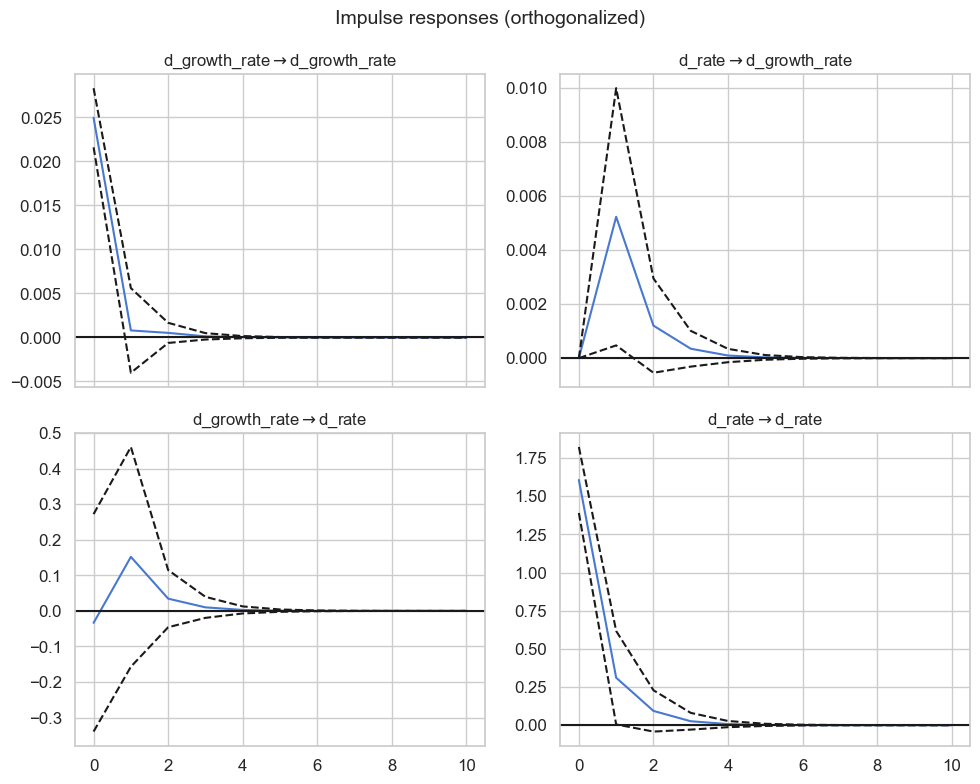

In [187]:
import matplotlib.pyplot as plt

# 1. Рассчитываем импульсные отклики на 10 месяцев вперед
# orth=True применяет ортогонализацию Холецкого для корректного разделения шоков
irf = results_var.irf(periods=10)

# 2. Строим графики (программа автоматически построит сетку 2х2)
fig = irf.plot(orth=True, figsize=(10, 8))

# 3. Делаем графики более читаемыми и аккуратными
plt.tight_layout()
plt.show()


# VECM

In [188]:
from statsmodels.tsa.vector_ar.vecm import select_order
from statsmodels.tsa.stattools import coint

print("=" * 60)
print("             2. ПОДБОР ЛАГОВ И ТЕСТ КОИНТЕГРАЦИИ           ")
print("=" * 60)

# 1. Подбор лагов для VAR в уровнях
# Используем 'co', так как ваш успешный тест Йохансена был без линейного тренда
lag_selection = select_order(merged_df[['growth_rate', 'rate']], maxlags=10, deterministic='co')
print(lag_selection.summary())

# Корректное извлечение рекомендаций критериев из объекта select_order
aic_lag = lag_selection.selected_orders['aic']
bic_lag = lag_selection.selected_orders['bic']
print(f"\nРекомендуемый лаг в уровнях по AIC: {aic_lag}")
print(f"Рекомендуемый лаг в уровнях по BIC: {bic_lag}")

# 2. Расчет лага для VECM (k_ar_diff = p - 1)
# Внимание: Финальный лаг мы принудительно зафиксируем равным 1 в следующей ячейке, 
# так как при лаге 0 тест Бройша-Годфри находит автокорреляцию!
print("-" * 60)

# 3. Строгий тест Энгла-Грейнджера (помним, что rate — зависимая переменная!)
# trend='c' означает наличие константы в долгосрочной связи
score, pvalue, crit_value = coint(merged_df['rate'], merged_df['growth_rate'], trend='c', maxlag=1)
print(f"t-статистика теста Энгла-Грейнджера: {score:.4f}")
print(f"Правильное p-value коинтеграции: {pvalue:.4f}")
print(f"Критические значения:")
print(f"  1%: {crit_value[0]:.4f}")
print(f"  5%: {crit_value[1]:.4f}")
print(f"  10%: {crit_value[2]:.4f}")
print("-" * 60)

if pvalue < 0.05:
    print("✅ Заключение: Коинтеграция ПОДТВЕРЖДЕНА! Ряды движутся вместе. Строим VECM.")
else:
    print("❌ Заключение: Коинтеграции НЕТ. Модель VECM строить нельзя.")
print("=" * 60)


             2. ПОДБОР ЛАГОВ И ТЕСТ КОИНТЕГРАЦИИ           
 VECM Order Selection (* highlights the minimums) 
       AIC         BIC         FPE         HQIC   
--------------------------------------------------
0       -6.142     -5.929*    0.002151      -6.056
1      -6.225*      -5.907   0.001979*     -6.097*
2       -6.183      -5.758    0.002066      -6.011
3       -6.168      -5.637    0.002099      -5.953
4       -6.122      -5.485    0.002200      -5.864
5       -6.049      -5.306    0.002370      -5.749
6       -5.977      -5.128    0.002551      -5.634
7       -5.908      -4.952    0.002742      -5.521
8       -5.850      -4.789    0.002914      -5.421
9       -5.814      -4.646    0.003033      -5.342
10      -5.762      -4.488    0.003212      -5.247
--------------------------------------------------

Рекомендуемый лаг в уровнях по AIC: 1
Рекомендуемый лаг в уровнях по BIC: 0
------------------------------------------------------------
t-статистика теста Энгла-Грейнджера: 

In [189]:
from statsmodels.tsa.vector_ar.vecm import VECM

print("=" * 75)
print("                 3. ОЦЕНКА ФИНАЛЬНОЙ МОДЕЛИ VECM                           ")
print("=" * 75)

# Вручную выставляем k_ar_diff=1. 
# Обоснование: при k_ar_diff=0 остатки модели не являются белым шумом (есть автокорреляция).
# deterministic='co' — константа внутри коинтеграционного вектора (соответствует вашему тесту Йохансена)
final_vecm_lag = 0

model_vecm = VECM(
    data_vecm[['growth_rate', 'rate']], 
    k_ar_diff=final_vecm_lag, 
    coint_rank=1, 
    deterministic='co'
)
results_vecm = model_vecm.fit()

print(results_vecm.summary())
print("=" * 75)


                 3. ОЦЕНКА ФИНАЛЬНОЙ МОДЕЛИ VECM                           
Det. terms outside the coint. relation & lagged endog. parameters for equation growth_rate
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0072      0.008      0.946      0.344      -0.008       0.022
Det. terms outside the coint. relation & lagged endog. parameters for equation rate
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -1.0403      0.473     -2.199      0.028      -1.967      -0.113
            Loading coefficients (alpha) for equation growth_rate             
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ec1            0.0005      0.001      

In [190]:
import scipy.stats as stats
from statsmodels.stats.diagnostic import het_arch

print("="*75)
print("             КОМПЛЕКСНАЯ ДИАГНОСТИКА ОСТАТКОВ МОДЕЛИ VECM            ")
print("="*75)

# Извлекаем остатки финальной модели VECM
residuals_vecm = results_vecm.resid
var_names = ['growth_rate (Денежная масса)', 'rate (Ключевая ставка)']

# 1. СИСТЕМНЫЙ ТЕСТ БРОЙША-ГОДФРИ (Whiteness Test)
# Проверяет автокорреляцию сразу во всей системе уравнений
bg_test = results_vecm.test_whiteness(nlags=4)
print("1. СИСТЕМНЫЙ ТЕСТ БРОЙША-ГОДФРИ НА АВТОКОРРЕЛЯЦИЮ:")
print(f"   Статистика теста: {bg_test.test_statistic:.4f}")
print(f"   p-value:          {bg_test.pvalue:.4f}")
print("   Вывод: ", "Остатки — белый шум (автокорреляции нет)" if bg_test.pvalue > 0.05 else "Присутствует автокорреляция остатков")
print("-" * 75)

# 2. ПОКОМПОНЕНТНЫЙ ТЕСТ ЛЬЮНГА-БОКСА
# Дополнительно проверяет автокорреляцию для каждого уравнения отдельно
print("2. ПОКОМПОНЕНТНЫЙ ТЕСТ ЛЬЮНГА-БОКСА (на 4 лага):")
for i, name in enumerate(var_names):
    lb_test = acorr_ljungbox(residuals_vecm[:, i], lags=[4], return_df=True)
    lb_pvalue = lb_test['lb_pvalue'].values[0]
    print(f"   Переменная {name}: p-value = {lb_pvalue:.4f} ->", 
          "Автокорреляция отсутствует" if lb_pvalue > 0.05 else "Есть автокорреляция")
print("-" * 75)

# 3. СИСТЕМНЫЙ ТЕСТ ХАРКЕ-БЕРА НА НОРМАЛЬНОСТЬ
# Проверяет нормальность распределения ошибок всей системы
jb_test = results_vecm.test_normality()
print("3. СИСТЕМНЫЙ ТЕСТ ХАРКЕ-БЕРА НА НОРМАЛЬНОСТЬ:")
print(f"   Статистика теста: {jb_test.test_statistic:.4f}")
print(f"   p-value:          {jb_test.pvalue:.4f}")
print("   Вывод: ", "Ошибки распределены нормально" if jb_test.pvalue > 0.05 else "Распределение остатков отличается от нормального")
print("-" * 75)

# 4. ПОКОМПОНЕНТНЫЙ ТЕСТ ШАПИРО-УИЛКА НА НОРМАЛЬНОСТЬ
print("4. ТЕСТ ШАПИРО-УИЛКА ДЛЯ КАЖДОГО УРАВНЕНИЯ:")
for i, name in enumerate(var_names):
    shapiro_stat, shapiro_p = stats.shapiro(residuals_vecm[:, i])
    print(f"   Переменная {name}: p-value = {shapiro_p:.4f} ->", 
          "Распределение нормальное" if shapiro_p > 0.05 else "Отличается от нормального")
print("-" * 75)

# 5. ARCH-LM ТЕСТ НА УСЛОВНУЮ ГЕТЕРОС КЕДАСТИЧНОСТЬ
# Проверяет стабильность дисперсии ошибок во времени
print("5. ARCH-LM ТЕСТ НА УСЛОВНУЮ ГЕТЕРОСКЕДАСТИЧНОСТЬ:")
for i, name in enumerate(var_names):
    # het_arch возвращает: lm_stat, lm_pvalue, f_stat, f_pvalue
    arch_res = het_arch(residuals_vecm[:, i], nlags=4)
    print(f"   Переменная {name}: p-value = {arch_res[1]:.4f} ->", 
          "Остатки гомоскедастичны (стабильны)" if arch_res[1] > 0.05 else "Присутствует ARCH-эффект волатильности")
print("="*75)


             КОМПЛЕКСНАЯ ДИАГНОСТИКА ОСТАТКОВ МОДЕЛИ VECM            
1. СИСТЕМНЫЙ ТЕСТ БРОЙША-ГОДФРИ НА АВТОКОРРЕЛЯЦИЮ:
   Статистика теста: 26.7376
   p-value:          0.0208
   Вывод:  Присутствует автокорреляция остатков
---------------------------------------------------------------------------
2. ПОКОМПОНЕНТНЫЙ ТЕСТ ЛЬЮНГА-БОКСА (на 4 лага):
   Переменная growth_rate (Денежная масса): p-value = 0.6723 -> Автокорреляция отсутствует
   Переменная rate (Ключевая ставка): p-value = 0.0391 -> Есть автокорреляция
---------------------------------------------------------------------------
3. СИСТЕМНЫЙ ТЕСТ ХАРКЕ-БЕРА НА НОРМАЛЬНОСТЬ:
   Статистика теста: 5706.5755
   p-value:          0.0000
   Вывод:  Распределение остатков отличается от нормального
---------------------------------------------------------------------------
4. ТЕСТ ШАПИРО-УИЛКА ДЛЯ КАЖДОГО УРАВНЕНИЯ:
   Переменная growth_rate (Денежная масса): p-value = 0.0000 -> Отличается от нормального
   Переменная rate (Ключевая 

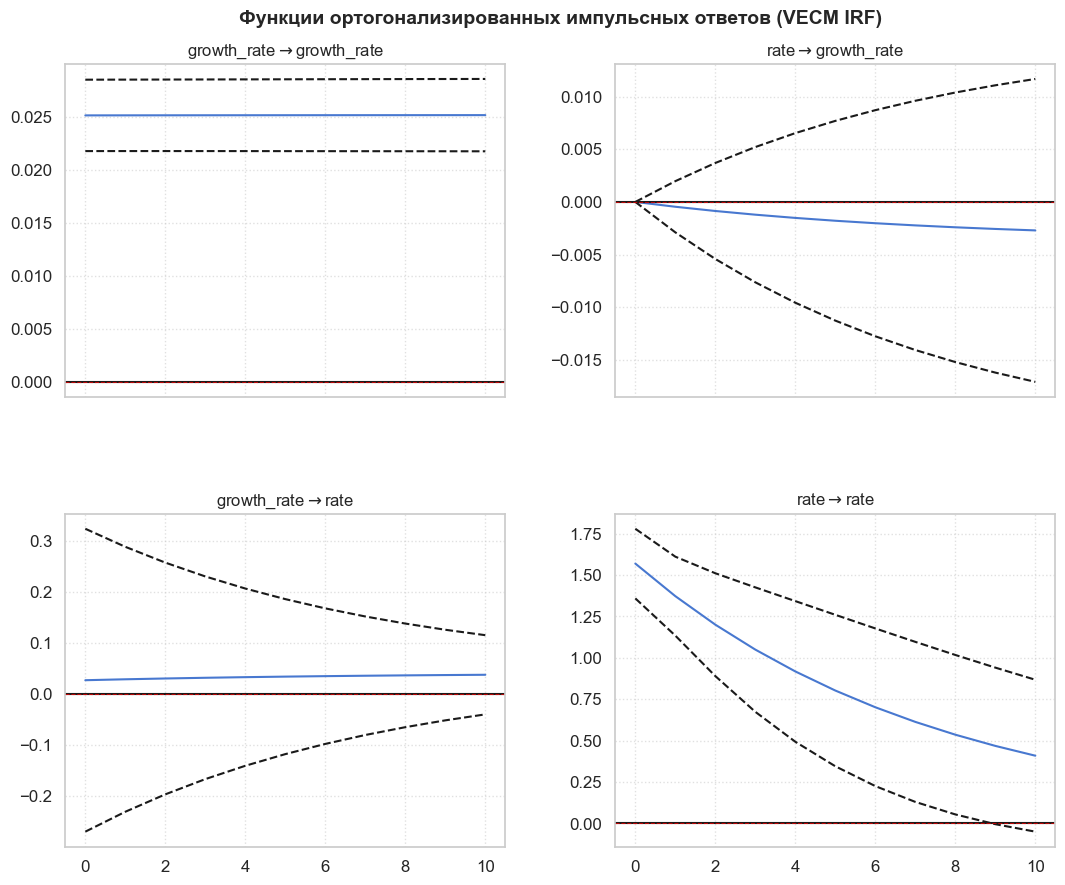

In [191]:
import matplotlib.pyplot as plt

# 1. Рассчитываем импульсные ответы на 10 периодов (месяцев) вперед
irf_vecm = results_vecm.irf(periods=10)

# 2. Строим графики с 95%-ми доверительными интервалами (signif=0.05)
# orth=True применяет декомпозицию Холецкого для ортогонализации шоков
fig = irf_vecm.plot(orth=True, signif=0.05, figsize=(11, 9))

# 3. Настройка оформления и читаемости
plt.subplots_adjust(top=0.92, hspace=0.35, wspace=0.25)
fig.suptitle('Функции ортогонализированных импульсных ответов (VECM IRF)', fontsize=14, fontweight='bold')

# Добавляем горизонтальную линию нуля на каждый подграфик для наглядности затухания шоков
for ax in fig.get_axes():
    ax.axhline(0, color='red', linestyle='--', linewidth=0.8, alpha=0.7)
    ax.grid(True, linestyle=':', alpha=0.6)

plt.show()


In [192]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, coint
from statsmodels.tsa.vector_ar.vecm import coint_johansen

# Предполагается, что ваш DataFrame называется merged_df
# Выделяем переменные и удаляем пропуски (важно для корректности тестов)
df_clean = merged_df[["rate", "growth_rate"]].dropna()

print("=== 1. ДВУХШАГОВЫЙ ТЕСТ ЭНГЛА-ГРЕЙНДЖЕРА ===")
# statsmodels.tsa.stattools.coint проверяет нулевую гипотезу: "Коинтеграции НЕТ"
# trend='c' означает, что в регрессию уровней включается константа
score, p_value, crit_values = coint(
    df_clean["growth_rate"], df_clean["rate"], trend="c"
)

print(f"t-статистика теста: {score:.4f}")
print(f"p-value: {p_value:.4f}")
print(
    f"Критические значения: 1%={crit_values[0]:.2f}, 5%={crit_values[1]:.2f}, 10%={crit_values[2]:.2f}"
)
if p_value < 0.05:
    print(
        "-> Отклоняем нуль-гипотезу: коинтеграция ОБНАРУЖЕНА (остатки стационарны)."
    )
else:
    print(
        "-> Не отклоняем нуль-гипотезу: коинтеграции НЕТ (остатки нестационарны)."
    )


print("\n=== 2. ТЕСТ ЙОХАНСЕНА ===")
# det_order=0 означает наличие константы внутри коинтеграционного соотношения (модель 2/3 по Хансену)
# k_ar_diff=1 означает 1 лаг в разностях (соответствует VAR(2) в уровнях). Подберите лаг по AIC/BIC!
johansen_test = coint_johansen(df_clean[["rate", "growth_rate"]], det_order=0, k_ar_diff=1)

# Вывод результатов Trace Statistic (Статистика следа)
print("Результаты Trace Statistic:")
print("Гипотеза | Статистика | 90% крит. | 95% крит. | 99% крит.")
for i in range(len(johansen_test.lr1)):
    r = i
    print(
        f"  r <= {r}  |   {johansen_test.lr1[i]:.2f}    |   {johansen_test.cvt[i][0]:.2f}    |   {johansen_test.cvt[i][1]:.2f}    |   {johansen_test.cvt[i][2]:.2f}"
    )

# Вывод результатов Max-Eigenvalue Statistic (Максимальное собственное значение)
print("\nРезультаты Max-Eigenvalue Statistic:")
print("Гипотеза | Статистика | 90% крит. | 95% крит. | 99% крит.")
for i in range(len(johansen_test.lr2)):
    r = i
    print(
        f"  r == {r}  |   {johansen_test.lr2[i]:.2f}    |   {johansen_test.cvm[i][0]:.2f}    |   {johansen_test.cvm[i][1]:.2f}    |   {johansen_test.cvm[i][2]:.2f}"
    )


=== 1. ДВУХШАГОВЫЙ ТЕСТ ЭНГЛА-ГРЕЙНДЖЕРА ===
t-статистика теста: 0.4023
p-value: 0.9919
Критические значения: 1%=-4.00, 5%=-3.39, 10%=-3.08
-> Не отклоняем нуль-гипотезу: коинтеграции НЕТ (остатки нестационарны).

=== 2. ТЕСТ ЙОХАНСЕНА ===
Результаты Trace Statistic:
Гипотеза | Статистика | 90% крит. | 95% крит. | 99% крит.
  r <= 0  |   12.55    |   13.43    |   15.49    |   19.93
  r <= 1  |   0.00    |   2.71    |   3.84    |   6.63

Результаты Max-Eigenvalue Statistic:
Гипотеза | Статистика | 90% крит. | 95% крит. | 99% крит.
  r == 0  |   12.55    |   12.30    |   14.26    |   18.52
  r == 1  |   0.00    |   2.71    |   3.84    |   6.63
